# Projet 8 – Recherche sémantique dans des documents universitaires (français, anglais, somali)

**Binôme :** Kenedid Yacin Boulaleh et Abdoulrazack Houssein Mahamoud
**Module :** TALN – M2 IAMD – Université de Djibouti

## 1. Introduction et problème

**Question.** Un étudiant écrit une question avec ses propres mots, en français, en anglais ou en somali. Peut-on retrouver automatiquement les passages des documents universitaires qui répondent à sa question ?

Deux difficultés :
- l'étudiant n'emploie pas toujours les mots du document : il écrit « je n'ai plus d'argent pour ma scolarité » alors que le règlement parle de « difficulté financière » et d'« étalement » ;
- il peut poser sa question dans une autre langue que celle du document (une question en anglais sur un règlement rédigé en français).

**Ce qu'on compare :**
1. **Baseline** : TF-IDF + similarité cosinus.
2. **Approche 2** : embeddings de phrases multilingues, avec deux modèles : `multilingual-e5-small` et `LaBSE`.
3. *(facultatif)* un mélange de TF-IDF avec chacun de ces modèles.

**Comment on mesure :** Precision@3, Hit@3 et MRR sur un jeu de requêtes avec les passages attendus, puis une analyse des erreurs.

> **Données synthétiques.** Les documents et les requêtes de ce projet sont **inventés** pour l'exercice (l'énoncé autorise les données synthétiques). Les règles décrites (frais, absences, bibliothèque...) ne sont pas celles d'une vraie université. Les scores obtenus mesurent la méthode sur ce petit corpus, pas la qualité d'un système réel.

### Plan du notebook

Le sujet demande toute la chaîne de traitement : **données → prétraitement → représentation → baseline → modèle → évaluation → analyse d'erreurs → démonstration**. Voici où se trouve chaque étape.

| Étape | Section du notebook |
|---|---|
| Données | 3 |
| Prétraitement | 4, puis 5 (langue des requêtes) et 6 (étude contrôlée) |
| Représentation | 6 (TF-IDF), 7 (embeddings) |
| Baseline | 6 |
| Modèle (approche 2) | 7 |
| Évaluation | 5 (requêtes, dev et test), 8 |
| Analyse d'erreurs | 9 |
| Démonstration et application | 10, 11 et application Django |

Les encodeurs pré-entraînés sont utilisés tels quels, sans entraînement : 232 passages sont trop peu pour entraîner ou ajuster un réseau de neurones.

## 2. Environnement, paramètres et imports

Ce notebook est prévu pour **Google Colab**, où l'approche 2 (embeddings) est activée automatiquement. Sur Colab, la première cellule installe les bibliothèques et demande de téléverser le fichier `data.zip` (le dossier `data/` compressé). Sur un ordinateur local, elle ne fait rien et l'approche 2 reste désactivée.

In [1]:
import subprocess
import sys
import zipfile
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    # 1) bibliothèques absentes de Colab (transformers < 5)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers<5", "sentence-transformers", "pypdf"], check=True)
    # 2) données : téléverser data.zip une seule fois
    if not Path("data/documents").exists():
        from google.colab import files
        print("Choisis le fichier data.zip sur ton ordinateur :")
        for nom in files.upload():
            zipfile.ZipFile(nom).extractall(".")

print("Colab :", EN_COLAB, "| dossier data/documents trouvé :", Path("data/documents").exists())

Choisis le fichier data.zip sur ton ordinateur :


Saving data.zip to data.zip
Colab : True | dossier data/documents trouvé : True


In [2]:
import re
import unicodedata
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ---- Paramètres du projet (tout se règle ici) ----
DOSSIER_DOCS = Path("data/documents")                  # un fichier .txt par document (nom_langue.txt)
FICHIER_ANNOTATIONS = Path("data/annotations.csv")     # colonnes : id (du passage), faits
FICHIER_REQUETES = Path("data/requetes.csv")           # colonnes : id, requete, langue, type, faits, partition
K = 3                         # nombre de passages affichés / évalués
UTILISER_EMBEDDINGS = EN_COLAB   # approche 2 : active sur Colab (télécharge environ 470 Mo + 1,8 Go)
MODELES_EMB = {                  # nom de la méthode -> modèle et préfixes demandés par sa fiche
    "embeddings": dict(nom="intfloat/multilingual-e5-small", prefixe_requete="query: ", prefixe_passage="passage: "),
    "labse": dict(nom="sentence-transformers/LaBSE", prefixe_requete="", prefixe_passage=""),
}
GRAINE = 42
np.random.seed(GRAINE)

## 3. Données et préparation

**Provenance.** Corpus **synthétique** : 14 documents universitaires fictifs d'une à quatre pages, dans le style des règlements et guides d'une université qui applique le système LMD. Ils ont été rédigés pour ce projet avec l'aide d'un assistant d'IA, puis sont à relire par les membres du binôme. Dates, montants et règles sont inventés. **Le somali doit être relu par un locuteur** avant le rendu.

| Langue | Documents |
|---|---|
| Français (7) | règlement des études et des examens, guide d'inscription, frais de scolarité et bourses, syllabus du Master IAMD, calendrier universitaire, charte informatique, guide des stages et du mémoire |
| Anglais (2) | règlement de la bibliothèque, guide de l'étudiant international |
| Somali (5) | guide de l'étudiant (hagaha ardayga), informations brèves pour les étudiants, règlement des études et des examens, frais et aides financières, règles d'usage de l'informatique |

**Découpage.** Un **passage** = une section d'un document (un article, un paragraphe numéroté), avec son titre. C'est le découpage naturel d'un règlement. Chaque fichier `.txt` du dossier `data/documents/` contient des blocs séparés par une ligne vide.

**Formats.** Chaque document existe en deux versions au contenu identique : un **PDF** (`data/documents_pdf/`), tel qu'un étudiant le consulterait, et un **.txt** (`data/documents/`), que le programme lit. Une cellule ci-dessous relit les PDF avec `pypdf` pour vérifier que le texte extrait contient bien tous les passages.

**Annotation.** Le fichier `data/annotations.csv` indique, pour chaque passage, le ou les **faits** qu'il contient. Un **fait** est une information précise (par exemple `certificat_medical` : le certificat se dépose sous trois jours). Un même fait peut apparaître dans plusieurs documents et plusieurs langues, avec des mots différents (ce ne sont pas des traductions mot à mot). Les passages sans fait (préambules, contacts) servent de bruit, comme dans un vrai document.

**Pièges voulus.** Des faits voisins existent (paiement, reçu, étalement, remboursement ; mot de passe et compte bloqué ; absence et certificat médical) et certains faits n'existent que dans une seule langue, ce qui permet de tester la recherche **entre langues**.

In [3]:
def nettoyer(texte):
    """Nettoyage léger : Unicode NFC et espaces propres. La version complète (clean_text) est testée en section 4 : sur ce corpus elle donne le même résultat."""
    texte = unicodedata.normalize("NFC", str(texte))
    return re.sub(r"\s+", " ", texte).strip()


def lire_blocs(chemin):
    """Un document .txt -> liste de passages. Un passage = un bloc séparé par une ligne vide.
    Les lignes qui commencent par # sont des commentaires et sont ignorées."""
    lignes = [l for l in chemin.read_text(encoding="utf-8").splitlines() if not l.startswith("#")]
    return [b.strip() for b in re.split(r"\n\s*\n", "\n".join(lignes)) if b.strip()]


lignes = []
for chemin in sorted(DOSSIER_DOCS.glob("*.txt")):
    langue = chemin.stem.rsplit("_", 1)[-1]                  # reglement_etudes_fr -> fr
    for n, bloc in enumerate(lire_blocs(chemin), start=1):
        lignes.append({
            "id": f"{chemin.stem}-{n:02d}", "source": chemin.name, "langue": langue,
            "titre": bloc.splitlines()[0], "texte": nettoyer(bloc),
        })
passages = pd.DataFrame(lignes)

annotations = pd.read_csv(FICHIER_ANNOTATIONS, encoding="utf-8-sig").fillna("")
inconnus = set(annotations["id"]) - set(passages["id"])
assert not inconnus, f"annotations sans passage : {inconnus}"
passages = passages.merge(annotations, on="id", how="left").fillna({"faits": ""})

nb_mots = passages["texte"].str.split().str.len()
print("Documents :", passages["source"].nunique(), "| Passages :", len(passages))
print("Passages par langue :", passages["langue"].value_counts().to_dict())
print("Longueur d'un passage (mots) : moyenne", round(nb_mots.mean(), 1), "| min", nb_mots.min(), "| max", nb_mots.max())
print("Passages sans fait annoté (préambules, contacts) :", int((passages["faits"] == "").sum()))
passages[["id", "langue", "titre", "faits"]].head(8)

Documents : 14 | Passages : 232
Passages par langue : {'fr': 123, 'so': 67, 'en': 42}
Longueur d'un passage (mots) : moyenne 54.1 | min 32 | max 77
Passages sans fait annoté (préambules, contacts) : 21


,id,langue,titre,faits
0,calendrier_universitaire_fr-01,fr,CALENDRIER UNIVERSITAIRE 2026-2027,
1,calendrier_universitaire_fr-02,fr,Inscriptions,periode_inscription
2,calendrier_universitaire_fr-03,fr,Rentrée et début du semestre 1,debut_cours
3,calendrier_universitaire_fr-04,fr,Pause de fin d'année,pause_hiver
4,calendrier_universitaire_fr-05,fr,Examens du semestre 1,dates_examens_s1
5,calendrier_universitaire_fr-06,fr,Délibérations et résultats du semestre 1,dates_resultats
6,calendrier_universitaire_fr-07,fr,Semestre 2,dates_semestre2
7,calendrier_universitaire_fr-08,fr,Examens du semestre 2,dates_examens_s2


In [4]:
# Vérification : les PDF contiennent le même texte que les fichiers .txt lus par le programme
from pypdf import PdfReader

norm = lambda s: " ".join(s.split())
lignes_pdf = []
for chemin in sorted(Path("data/documents_pdf").glob("*.pdf")):
    lecteur = PdfReader(str(chemin))
    texte_pdf = norm(" ".join(p.extract_text() or "" for p in lecteur.pages))
    doc = passages[passages["source"] == chemin.stem + ".txt"]
    lignes_pdf.append({
        "pdf": chemin.name, "pages": len(lecteur.pages), "passages": len(doc),
        "retrouvés_dans_le_pdf": sum(norm(t) in texte_pdf for t in doc["texte"]),
    })
verif_pdf = pd.DataFrame(lignes_pdf)
print("PDF :", len(verif_pdf), "| passages retrouvés :", verif_pdf["retrouvés_dans_le_pdf"].sum(), "/", verif_pdf["passages"].sum())
verif_pdf

PDF : 14 | passages retrouvés : 232 / 232


,pdf,pages,passages,retrouvés_dans_le_pdf
0,calendrier_universitaire_fr.pdf,2,13,13
1,charte_informatique_fr.pdf,2,16,16
2,frais_bourses_fr.pdf,2,16,16
3,guide_ardayga_so.pdf,3,22,22
4,guide_inscription_fr.pdf,3,18,18
5,guide_stage_memoire_fr.pdf,2,16,16
6,lacagaha_iyo_caawimaadda_so.pdf,1,7,7
7,library_rules_en.pdf,2,14,14
8,macluumaad_kooban_so.pdf,2,15,15
9,reglement_etudes_fr.pdf,4,26,26


In [5]:
# Quels faits existent dans quelles langues ?
faits_long = passages.assign(fait=passages["faits"].str.split(";")).explode("fait")
faits_long = faits_long[faits_long["fait"] != ""]
couverture = pd.crosstab(faits_long["fait"], faits_long["langue"])
print("Faits différents :", len(couverture))
print("Nombre de faits selon le nombre de langues :")
print(couverture.gt(0).sum(axis=1).value_counts().sort_index().rename("faits").to_frame().T)
print("\nFaits présents dans une seule langue :")
unique = couverture[couverture.gt(0).sum(axis=1) == 1]
print(unique.idxmax(axis=1).to_dict())

Faits différents : 131
Nombre de faits selon le nombre de langues :
        1   2   3
faits  65  46  20

Faits présents dans une seule langue :
{'acceptation_charte': 'fr', 'anonymat': 'fr', 'assurance_stage': 'fr', 'bourse_montant': 'fr', 'bourse_pieces': 'fr', 'candidature_master': 'fr', 'candidature_stage': 'fr', 'carte_bibliotheque': 'en', 'competences_visees': 'fr', 'conduite_bibliotheque': 'en', 'controle_continu': 'fr', 'criteres_selection': 'fr', 'dates_examens_s1': 'fr', 'dates_examens_s2': 'fr', 'dates_resultats': 'fr', 'dates_semestre2': 'fr', 'dates_soutenance': 'fr', 'debouches': 'fr', 'debut_cours': 'fr', 'depot_memoire': 'fr', 'dossier_incomplet': 'fr', 'encadrement': 'fr', 'evaluation_stage': 'fr', 'evaluation_syllabus': 'fr', 'fraude': 'fr', 'gratification_stage': 'fr', 'horaires_scolarite': 'fr', 'jours_feries': 'fr', 'lettre_admission': 'en', 'lieux_stage': 'fr', 'logement': 'en', 'mentions': 'fr', 'modification_calendrier': 'fr', 'module_dl': 'fr', 'module_ethique':

## 4. Prétraitement

**Objectif.** Dire précisément ce qu'on fait au texte avant de le représenter, mesurer l'effet de chaque choix et le justifier avec les données.

**Principes suivis :**
1. garder un texte brut intact (*raw*), puis un texte nettoyé (*interim*), puis les représentations calculées (*processed*) ;
2. mesurer **avant et après** (passages, tokens, types, doublons, URL, e-mails) ;
3. contrôler : tests unitaires et inspection manuelle d'un échantillon ;
4. justifier chaque transformation par la langue, le domaine et la tâche, pas par une recette universelle ;
5. pour les modèles neuronaux : prétraitement léger et tokenizer du modèle.

| Niveau | Où dans le projet | Contenu |
|---|---|---|
| raw | `data/documents/*.txt` et `data/documents_pdf/*.pdf` | jamais modifiés par le programme |
| interim | DataFrame `passages` (colonne `texte`) | un passage par ligne, nettoyé, avec langue, source et faits |
| processed | `artefacts/` (écrit en section 11) | vectoriseur et matrice TF-IDF, embeddings `.npy`, `passages.csv` |

On décrit aussi le corpus par des métadonnées (origine, mode de collecte, date, licence) :

In [6]:
# Fiche du corpus : origine, mode de collecte, langue, domaine, date, licence
fiche = pd.DataFrame([
    ("origine", "corpus synthétique : documents universitaires fictifs, inventés pour ce projet"),
    ("mode de collecte", "rédigés avec l'aide d'un assistant d'IA, à relire par le binôme ; le somali doit être relu par un locuteur"),
    ("date de constitution", "novembre 2026"),
    ("domaine", "vie universitaire : règlements, inscription, frais, bibliothèque, informatique, stages, calendrier"),
    ("langues", ", ".join(f"{l} : {n} passages" for l, n in passages["langue"].value_counts().items())),
    ("unités", f"{passages['source'].nunique()} documents, {len(passages)} passages (une section = un passage)"),
    ("formats (raw)", "un .txt et un .pdf au contenu identique par document ; annotations et requêtes en CSV"),
    ("annotation", f"un ou plusieurs faits par passage, notés lors de la rédaction ({int((passages['faits'] != '').sum())} passages annotés)"),
    ("données personnelles", "aucune (contenu inventé)"),
    ("licence", "contenu inventé, sans droits de tiers, usage pédagogique (licence exacte à préciser par le binôme)"),
], columns=["champ", "valeur"])
print(fiche.to_string(index=False))

               champ                                                                                                     valeur
             origine                             corpus synthétique : documents universitaires fictifs, inventés pour ce projet
    mode de collecte rédigés avec l'aide d'un assistant d'IA, à relire par le binôme ; le somali doit être relu par un locuteur
date de constitution                                                                                              novembre 2026
             domaine         vie universitaire : règlements, inscription, frais, bibliothèque, informatique, stages, calendrier
             langues                                                      fr : 123 passages, so : 67 passages, en : 42 passages
              unités                                                      14 documents, 232 passages (une section = un passage)
       formats (raw)                      un .txt et un .pdf au contenu identique par document ; annotat

### 4.1 Nettoyage

On utilise la fonction `clean_text` : entités HTML, Unicode NFC, balises, caractères de contrôle, espaces. **Deux choix sont à justifier :**

- **URL et e-mails.** On les remplace d'habitude par `<URL>` et `<EMAIL>`, ce qui convient pour classer des textes. Pour une recherche, l'adresse d'un service peut être justement la réponse attendue : on les **garde** par défaut (option `remplacer_url_email`). Notre corpus n'en contient aucun.
- **Minuscules et accents.** On ne les applique pas au texte stocké. Ils sont réglés dans le vectoriseur TF-IDF et testés en section 6 ; les modèles d'embeddings reçoivent le texte avec casse et accents (prétraitement léger).

Notre corpus synthétique est propre : pour vraiment tester la fonction, les tests ci-dessous utilisent des cas sales (HTML, e-mail, espace insécable, caractère de contrôle, accent combinant), comme en produirait une extraction de page web ou de PDF.

In [7]:
import html
from collections import Counter

# Expressions régulières de nettoyage, compilées une seule fois
CONTROL_RE = re.compile(r"[\x00-\x08\x0B\x0C\x0E-\x1F\x7F]")
SPACE_RE = re.compile(r"\s+")
URL_RE = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
EMAIL_RE = re.compile(r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b")
TAG_RE = re.compile(r"<[^>]+>")


def clean_text(text, lowercase=False, remplacer_url_email=False):
    """Nettoyage de base. Un choix voulu : par défaut on ne remplace PAS les URL et e-mails
    par <URL> / <EMAIL>. Pour classer des textes, remplacer est préférable ; pour une recherche, l'adresse du
    service peut être justement la réponse attendue."""
    text = "" if text is None else str(text)
    text = html.unescape(text)
    text = unicodedata.normalize("NFC", text)
    text = TAG_RE.sub(" ", text)
    if remplacer_url_email:
        text = URL_RE.sub(" <URL> ", text)
        text = EMAIL_RE.sub(" <EMAIL> ", text)
    text = CONTROL_RE.sub(" ", text)
    text = SPACE_RE.sub(" ", text).strip()
    return text.casefold() if lowercase else text


def test_clean_text():
    """Tests unitaires : cas courants (espaces, None, URL, e-mail) et défauts propres à notre corpus."""
    assert clean_text(" Bonjour monde ") == "Bonjour monde"
    assert clean_text(None) == ""
    assert "<URL>" in clean_text("Voir https://example.org", remplacer_url_email=True)
    assert "<EMAIL>" in clean_text("Écrire à scolarite@univ.dj", remplacer_url_email=True)
    assert "https://example.org" in clean_text("Voir https://example.org")                 # par défaut : conservée
    assert clean_text("<p>Les frais</p> &amp; les bourses") == "Les frais & les bourses"   # balises et entités HTML
    assert clean_text("école") == "école"                                           # NFC : e + accent combinant -> é
    assert clean_text("a b\t c\n\nd") == "a b c d"                                   # espace insécable, tabulation, sauts de ligne
    assert clean_text("a\x00b") == "a b"                                                  # caractère de contrôle
    assert clean_text("Étudiant", lowercase=True) == "étudiant"                           # les accents sont conservés
    assert clean_text("Bàrashada Soomaaliga") == "Bàrashada Soomaaliga"                   # le somali n'est pas abîmé
    bruit = " <b>Bonjour</b> le monde "
    assert clean_text(clean_text(bruit)) == clean_text(bruit)                             # idempotent


test_clean_text()
print("test_clean_text : tous les tests passent")

# Exemple sur un texte volontairement sale (ce que donne parfois une extraction de page web ou de PDF)
sale = "<p>Écrire à  scolarite@univ.dj ou voir https://univ.example/frais&nbsp;:\ttarifs &amp; bourses</p>\x07"
print("avant      :", repr(sale))
print("remplacés  :", repr(clean_text(sale, remplacer_url_email=True)))
print("recherche  :", repr(clean_text(sale)))

test_clean_text : tous les tests passent
avant      : '<p>Écrire à  scolarite@univ.dj\xa0ou voir https://univ.example/frais&nbsp;:\ttarifs &amp; bourses</p>\x07'
remplacés  : 'Écrire à <EMAIL> ou voir <URL> : tarifs & bourses'
recherche  : 'Écrire à scolarite@univ.dj ou voir https://univ.example/frais : tarifs & bourses'


### 4.2 Segmentation et tokenisation

Un tokenizer doit être **évalué sur un échantillon réel de la langue et du domaine**. On compare six tokenizers sur des phrases prises dans le corpus (chacune contient une apostrophe). Le tableau ci-dessous montre le découpage du mot à apostrophe et le nombre de tokens de la phrase.

Ce qu'on observe :
- **L'apostrophe n'a pas le même rôle selon la langue.** En français c'est une élision (`l'année` = `l` + `année`), en anglais un possessif (`student's`), en somali elle fait partie du mot (`la'aantiis`, `hay'ad`, `su'aalo`). Aucune règle de découpage ne convient aux trois langues.
- **La regex de base** ne reconnaît que l'apostrophe typographique ’ ; nos fichiers utilisent l'apostrophe droite `'`. Elle coupe donc tous les mots à apostrophe, somali compris. NLTK fait de même.
- **spaCy français** coupe bien `l'` / `année` mais coupe aussi `la'` / `aantiis` en somali. **spaCy n'a pas de langue somali** : c'est un exemple concret de langue peu dotée.
- On garde la **regex adaptée** (apostrophe droite ou typographique à l'intérieur du mot) pour les statistiques et les essais de mots vides et de racines. Pour TF-IDF par caractères et pour les embeddings, aucun tokenizer de mots n'intervient.

In [8]:
# Tokenisation : on compare plusieurs tokenizers sur des phrases PRISES DANS LE CORPUS.
# Regex de base : elle ne reconnaît que l'apostrophe typographique ’ alors que nos fichiers utilisent l'apostrophe droite '.
TOKEN_RE_BASE = re.compile(r"[^\W\d_]+(?:[’-][^\W\d_]+)*|\d+(?:[.,]\d+)?|[^\w\s]", re.UNICODE)
TOKEN_RE = re.compile(r"[^\W\d_]+(?:['’-][^\W\d_]+)*|\d+(?:[.,]\d+)?|[^\w\s]", re.UNICODE)   # adaptée : ' et ’


def mots_de(texte):
    """Mots et nombres en minuscules, sans ponctuation (regex adaptée). Sert aux statistiques et aux essais ci-dessous."""
    return [t for t in TOKEN_RE.findall(texte.lower()) if t[0].isalnum()]


def phrase_avec_apostrophe(langue):
    """Première phrase du corpus (hors titre) qui contient une apostrophe au milieu d'un mot."""
    for _, p in passages[passages["langue"] == langue].iterrows():
        corps = p["texte"][len(p["titre"]):].strip()
        for phrase in re.split(r"(?<=[.!?])\s+", corps):
            if re.search(r"\w'\w", phrase):
                return phrase
    return ""


PHRASES = {langue: phrase_avec_apostrophe(langue) for langue in ["fr", "en", "so"]}
MOTS_TEST = {langue: re.search(r"\w+'\w+", phrase).group(0) for langue, phrase in PHRASES.items()}
for langue, phrase in PHRASES.items():
    print(langue, ":", phrase)

from nltk.tokenize import wordpunct_tokenize
import spacy

TOKENIZERS = {
    "split() (espaces)": lambda t: t.split(),
    "regex de base (’ seulement)": TOKEN_RE_BASE.findall,
    "regex adaptée (' et ’)": TOKEN_RE.findall,
    "NLTK wordpunct_tokenize": wordpunct_tokenize,
    "spaCy fr (pipeline vide)": lambda t, nlp=spacy.blank("fr"): [x.text for x in nlp(t)],
    "spaCy xx (multilingue, vide)": lambda t, nlp=spacy.blank("xx"): [x.text for x in nlp(t)],
}
lignes = []
for nom, f in TOKENIZERS.items():
    ligne = {"tokenizer": nom}
    for langue in ["fr", "en", "so"]:
        ligne[f"« {MOTS_TEST[langue]} » ({langue})"] = " | ".join(f(MOTS_TEST[langue]))
    for langue in ["fr", "en", "so"]:
        ligne[f"tokens phrase {langue}"] = len(f(PHRASES[langue]))
    lignes.append(ligne)
print()
print(pd.DataFrame(lignes).set_index("tokenizer").to_string())

try:
    spacy.blank("so")
except Exception as erreur:
    print("\nspaCy pour le somali :", type(erreur).__name__, "- aucune langue « so » disponible (langue peu dotée)")

fr : Ce calendrier fixe les grandes dates de l'année universitaire pour tous les étudiants de Master.
en : Online journals and databases are available from any computer on the campus network, and from outside the campus with the student's platform account.
so : Heshiiskaas la'aantiis tababarka lama aqoonsanayo.

                             « l'année » (fr) « student's » (en) « la'aantiis » (so)  tokens phrase fr  tokens phrase en  tokens phrase so
tokenizer                                                                                                                                 
split() (espaces)                     l'année          student's          la'aantiis                15                23                 5
regex de base (’ seulement)     l | ' | année    student | ' | s    la | ' | aantiis                18                27                 8
regex adaptée (' et ’)                l'année          student's          la'aantiis                16                25          

### 4.3 Contrôle qualité : mesures avant et après

On compare avant et après le nettoyage, on teste, on inspecte.

**Résultat.** Le nettoyage ne change que les **sauts de ligne** (232 passages, remplacés par des espaces). Aucun mot n'est supprimé (0 % de tokens supprimés), il n'y a aucun doublon, aucune URL, aucun e-mail, aucune balise. La fonction complète donne **exactement le même texte** que la fonction `nettoyer` du pipeline (section 3) pour les 232 passages : on garde donc la version légère.

Ce résultat est normal pour un corpus synthétique propre. Avec de vrais PDF ou de vraies pages web, il faudrait refaire ces mesures ; c'est pourquoi la fonction complète et ses tests sont conservés.

In [9]:
# Contrôle qualité du nettoyage : mesures AVANT / APRÈS sur tout le corpus
brut = [bloc for chemin in sorted(DOSSIER_DOCS.glob("*.txt")) for bloc in lire_blocs(chemin)]    # raw : blocs lus sans nettoyage
propre = [clean_text(b) for b in brut]                                                            # interim : après nettoyage
assert len(brut) == len(passages)


def mesures(textes):
    toks = [m for t in textes for m in mots_de(t)]
    return {
        "documents": passages["source"].nunique(),
        "passages": len(textes),
        "caractères": sum(len(t) for t in textes),
        "tokens (mots)": len(toks),
        "types (mots différents)": len(set(toks)),
        "longueur moyenne d'un passage (mots)": round(len(toks) / len(textes), 1),
        "URL": sum(len(URL_RE.findall(t)) for t in textes),
        "e-mails": sum(len(EMAIL_RE.findall(t)) for t in textes),
        "balises ou entités HTML": sum(len(TAG_RE.findall(t)) + len(re.findall(r"&\w+;|&#\d+;", t)) for t in textes),
        "caractères de contrôle": sum(len(CONTROL_RE.findall(t)) for t in textes),
        "retours à la ligne": sum(t.count("\n") for t in textes),
        "passages en double": len(textes) - len(set(textes)),
    }


tableau = pd.DataFrame({"avant": pd.Series(mesures(brut), dtype=object), "après": pd.Series(mesures(propre), dtype=object)})
tableau.loc["taux de tokens supprimés (%)"] = ["", round(100 * (1 - tableau.loc["tokens (mots)", "après"] / tableau.loc["tokens (mots)", "avant"]), 2)]
print(tableau.to_string())

modifies = sum(b != p for b, p in zip(brut, propre))
seulement_espaces = sum(" ".join(b.split()) == p for b, p in zip(brut, propre))
identiques = sum(clean_text(b) == nettoyer(b) for b in brut)
print(f"\nPassages modifiés par le nettoyage : {modifies} / {len(brut)} | dont changement d'espaces ou de sauts de ligne seulement : {seulement_espaces}")
print(f"clean_text (version complète) donne le même résultat que nettoyer (celle du pipeline) : {identiques} / {len(brut)} passages")

# Inspection manuelle d'un échantillon : un passage par langue, avant puis après
for langue in ["fr", "en", "so"]:
    i = passages.index[passages["langue"] == langue][0]
    print(f"\n[{langue}] avant :", repr(brut[i][:150]))
    print(f"[{langue}] après :", repr(propre[i][:150]))

                                      avant  après
documents                                14     14
passages                                232    232
caractères                            80278  80278
tokens (mots)                         12500  12500
types (mots différents)                3185   3185
longueur moyenne d'un passage (mots)   53.9   53.9
URL                                       0      0
e-mails                                   0      0
balises ou entités HTML                   0      0
caractères de contrôle                    0      0
retours à la ligne                      232      0
passages en double                        0      0
taux de tokens supprimés (%)                   0.0

Passages modifiés par le nettoyage : 232 / 232 | dont changement d'espaces ou de sauts de ligne seulement : 232
clean_text (version complète) donne le même résultat que nettoyer (celle du pipeline) : 232 / 232 passages

[fr] avant : "CALENDRIER UNIVERSITAIRE 2026-2027\nCe calendrier f

### 4.4 Statistiques par langue

Tokens, types et TTR par langue. **Prudence** : le TTR dépend de la longueur du texte. On compare donc aussi les langues sur le **même nombre de tokens** (2 427, la taille du sous-corpus anglais).

- À taille égale, le somali a le plus de types différents (880, contre 760 en français et 732 en anglais) : ses formes se répètent moins. C'est compatible avec la morphologie plus riche du somali, mais le corpus est petit et le somali a été rédigé avec l'aide d'une IA : **on ne conclut pas** que le somali est « plus riche ».
- Les formes les plus répandues sont des mots grammaticaux (*de, la, le, et* ; *the, and, is* ; *ah, la, waxaa, iyo, waa*). En somali figurent aussi des mots **de contenu** du domaine : `ardayga` (l'étudiant) dans 46 % des passages et `xafiiska` (le bureau) dans 39 %. Une liste de mots vides construite seulement sur la fréquence retirerait donc des mots utiles. On mesure l'effet réel en section 6.

In [10]:
# Statistiques par langue (tokens, types, TTR) sur le texte nettoyé
tokens_par_langue = {l: [m for t in sub["texte"] for m in mots_de(t)] for l, sub in passages.groupby("langue")}
N = min(len(t) for t in tokens_par_langue.values())          # taille commune : le TTR dépend de la longueur du texte
lignes = []
for langue, toks in tokens_par_langue.items():
    nb_passages = int((passages["langue"] == langue).sum())
    lignes.append({
        "langue": langue, "passages": nb_passages, "tokens": len(toks), "types": len(set(toks)),
        "TTR": round(len(set(toks)) / len(toks), 3),
        f"types sur les {N} premiers tokens": len(set(toks[:N])),
        f"TTR sur {N} tokens": round(len(set(toks[:N])) / N, 3),
        "mots par passage": round(len(toks) / nb_passages, 1),
    })
print(pd.DataFrame(lignes).set_index("langue").to_string())

# Formes les plus répandues : part des passages de la langue qui contiennent la forme (fréquence documentaire)
print("\nFormes présentes dans le plus de passages (part des passages de la langue) :")
for langue, sub in passages.groupby("langue"):
    c = Counter(m for t in sub["texte"] for m in set(mots_de(t)))
    print(f"  {langue} :", ", ".join(f"{m} ({n / len(sub):.0%})" for m, n in c.most_common(14)))

        passages  tokens  types    TTR  types sur les 2427 premiers tokens  TTR sur 2427 tokens  mots par passage
langue                                                                                                           
en            42    2427    732  0.302                                 732                0.302              57.8
fr           123    6943   1564  0.225                                 760                0.313              56.4
so            67    3130   1015  0.324                                 880                0.363              46.7

Formes présentes dans le plus de passages (part des passages de la langue) :
  en : the (100%), and (88%), is (83%), to (76%), a (76%), of (64%), at (60%), for (55%), in (52%), student (45%), on (43%), it (40%), not (38%), are (38%)
  fr : de (97%), la (88%), et (78%), les (78%), le (78%), est (67%), à (66%), du (59%), des (54%), un (51%), en (48%), au (46%), une (42%), sont (40%)
  so : ah (66%), la (63%), waxaa (58%), iyo (

### 4.5 Ce qu'on retient pour la suite

- **Nettoyage** : Unicode NFC et espaces ; on ne touche ni aux mots, ni aux accents, ni à la casse du texte stocké.
- **Tokenisation** : regex adaptée pour les statistiques ; pas de tokenizer de mots pour TF-IDF par caractères ni pour les embeddings.
- Deux étapes du prétraitement viennent après le chargement des requêtes : la **détection de la langue** (section 5) et l'**étude contrôlée** des variantes pour TF-IDF (section 6).

## 5. Jeu de requêtes d'évaluation

Chaque requête a :
- une **langue** (fr, en, so) ;
- un **type** : `mots_communs` (elle reprend des mots du passage), `paraphrase` (autres mots, même sens) ou `court` (très courte, sans accents ou abrégée) ;
- un **fait attendu** ;
- une **partition** : `dev` pour régler les paramètres, `test` pour le résultat final. On ne règle jamais sur le test, sinon le score est trop optimiste.

**Deux façons de décider quels passages sont « bons »** (deux scénarios) :
- **toutes_langues** : sont bons tous les passages qui expriment le fait attendu, quelle que soit leur langue. Ce scénario mesure la recherche entre langues.
- **meme_langue** : sont bons seulement les passages du fait attendu écrits dans la langue de la requête. Ce scénario correspond à un étudiant qui veut sa réponse dans sa langue. Les requêtes dont le fait n'existe pas dans leur langue sont écartées de ce scénario.

> Précaution : la Precision@3 ne peut pas atteindre 1 quand il y a moins de 3 bons passages (avec un seul bon passage, le maximum est 0,33). Pour comparer, on regarde surtout Hit@3 et MRR.

In [11]:
requetes = pd.read_csv(FICHIER_REQUETES, encoding="utf-8-sig")


def passages_attendus(faits, langue=None):
    """Ensemble des id de passages qui expriment le(s) fait(s), éventuellement dans une langue donnée."""
    voulus = set(str(faits).split(";"))
    sel = passages[passages["faits"].apply(lambda s: bool(voulus & set(s.split(";"))))]
    if langue is not None:
        sel = sel[sel["langue"] == langue]
    return set(sel["id"])


requetes["attendus_toutes"] = [passages_attendus(f) for f in requetes["faits"]]
requetes["attendus_meme"] = [passages_attendus(f, l) for f, l in zip(requetes["faits"], requetes["langue"])]
assert all(len(s) > 0 for s in requetes["attendus_toutes"]), "un fait attendu n'existe pas dans le corpus"

SCENARIOS = {"toutes_langues": "attendus_toutes", "meme_langue": "attendus_meme"}
CROISEES = set(requetes.loc[requetes["attendus_meme"].apply(len) == 0, "id"])

print(len(requetes), "requêtes")
print(requetes.groupby(["partition", "langue"]).size().unstack(fill_value=0))
print()
print(requetes.groupby(["partition", "type"]).size().unstack(fill_value=0))
print("\nRequêtes dont le fait n'existe pas dans leur langue :", len(CROISEES), sorted(CROISEES))
requetes[["id", "requete", "langue", "type", "faits", "partition"]].head(8)

83 requêtes
langue     en  fr  so
partition            
dev         6   6   8
test       16  22  25

type       court  mots_communs  paraphrase
partition                                 
dev            3             9           8
test           7            21          35

Requêtes dont le fait n'existe pas dans leur langue : 11 ['Q15', 'Q16', 'Q17', 'Q36', 'Q37', 'Q39', 'Q52', 'Q53', 'Q54', 'Q56', 'Q57']


,id,requete,langue,type,faits,partition
0,Q01,Quelles pièces faut-il fournir pour s'inscrire...,fr,mots_communs,dossier_inscription,dev
1,Q02,Combien coûtent les frais de scolarité en Mast...,fr,mots_communs,montant_frais,test
2,Q03,Peut-on payer les frais de scolarité en deux v...,fr,mots_communs,paiement_modalites,test
3,Q04,Comment réinitialiser mon mot de passe ?,fr,mots_communs,mot_de_passe,dev
4,Q05,Quelles sont les dates des examens du premier ...,fr,mots_communs,dates_examens_s1,test
5,Q06,Comment est calculée la note finale d'un module ?,fr,mots_communs,note_finale,test
6,Q07,Quel est le délai pour déposer un certificat m...,fr,mots_communs,certificat_medical,test
7,Q08,"Je n'ai plus d'argent pour payer ma scolarité,...",fr,paraphrase,etalement,test


### Contrôle de fuite entre dev et test

Laisser un quasi-duplicat des deux côtés est une fuite de données classique. Ici aucun modèle n'apprend sur les requêtes (TF-IDF et embeddings sont calculés sur les passages) : le risque est seulement de **régler** nos choix sur des requêtes proches de celles du test. Le contrôle ci-dessous montre que 9 faits sont visés à la fois par une requête dev et par une requête test (13 requêtes de test sur 63), mais qu'aucune requête n'est identique. Le réglage sur dev porte sur très peu de choix (variante de TF-IDF, poids du mélange), ce qui limite le risque ; il reste à signaler dans les limites.

In [12]:
# Contrôle de fuite entre dev et test (un quasi-duplicat des deux côtés fausserait le réglage)
faits_dev = {f for fs in requetes[requetes["partition"] == "dev"]["faits"] for f in fs.split(";")}
test_df = requetes[requetes["partition"] == "test"]
faits_test = {f for fs in test_df["faits"] for f in fs.split(";")}
partage = test_df["faits"].apply(lambda fs: any(f in faits_dev for f in fs.split(";")))
print(f"Faits visés par les requêtes dev : {len(faits_dev)} | par les requêtes test : {len(faits_test)} | communs : {len(faits_dev & faits_test)}")
print(f"Requêtes test dont le fait est aussi visé par une requête dev : {int(partage.sum())} / {len(test_df)}")
print("Requêtes identiques entre dev et test :", len(set(requetes[requetes['partition'] == 'dev']['requete']) & set(test_df['requete'])))

Faits visés par les requêtes dev : 15 | par les requêtes test : 44 | communs : 9
Requêtes test dont le fait est aussi visé par une requête dev : 13 / 63
Requêtes identiques entre dev et test : 0


### Langue des requêtes : détection

La **détection de langue** est une étape classique d'un moteur de recherche multilingue. On la traite comme une classification de textes : un classificateur appris sur les passages (étiquette = langue du fichier) et testé sur les 83 requêtes, jamais vues à l'apprentissage. La baseline est la classe majoritaire. Résultat : accuracy 0,976 et macro-F1 0,973, contre 0,337 et 0,168 pour la baseline. Les deux erreurs sont des requêtes de **deux mots** (`wifi campus`, `exam dates`), trop courtes pour décider.

La langue détectée sert à l'étude de la section 6 (racines selon la langue). Elle n'est **pas** utilisée par l'application Django ; ce serait une extension (filtrer ou classer les résultats selon la langue de la question).

In [13]:
# Détection de la langue de la requête (étape d'un moteur de recherche multilingue), faite comme une classification de textes :
# jeu d'entraînement = passages (étiquette = langue du fichier), jeu de test = les 83 requêtes, jamais vues à l'apprentissage.
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

ordre_langues = ["fr", "en", "so"]
resultats_langue = []
for nom, clf in [("Baseline (classe majoritaire)", DummyClassifier(strategy="most_frequent")),
                 ("TF-IDF caractères 1-3 + Naive Bayes", MultinomialNB(alpha=0.1))]:
    modele = Pipeline([("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3), lowercase=True)), ("clf", clf)])
    modele.fit(passages["texte"], passages["langue"])
    prediction = modele.predict(requetes["requete"])
    resultats_langue.append({"modèle": nom, "accuracy": accuracy_score(requetes["langue"], prediction),
                             "macro-F1": f1_score(requetes["langue"], prediction, average="macro")})
detecteur = modele                       # le dernier : Naive Bayes
print(pd.DataFrame(resultats_langue).set_index("modèle").round(3).to_string())

matrice = confusion_matrix(requetes["langue"], prediction, labels=ordre_langues)
print("\nMatrice de confusion (lignes = vraie langue, colonnes = langue prédite) :")
print(pd.DataFrame(matrice, index=ordre_langues, columns=ordre_langues).to_string())
erreurs_langue = requetes.assign(predite=prediction)
erreurs_langue = erreurs_langue[erreurs_langue["langue"] != erreurs_langue["predite"]]
print("\nRequêtes mal classées :")
print(erreurs_langue[["id", "langue", "predite", "requete", "partition"]].to_string(index=False))

LANGUE_DETECTEE = dict(zip(requetes["requete"], prediction))


def langue_de(requete):
    """Langue détectée d'une requête (mise en cache)."""
    if requete not in LANGUE_DETECTEE:
        LANGUE_DETECTEE[requete] = detecteur.predict([requete])[0]
    return LANGUE_DETECTEE[requete]

                                     accuracy  macro-F1
modèle                                                 
Baseline (classe majoritaire)           0.337     0.168
TF-IDF caractères 1-3 + Naive Bayes     0.976     0.973

Matrice de confusion (lignes = vraie langue, colonnes = langue prédite) :
    fr  en  so
fr  27   1   0
en   1  21   0
so   0   0  33

Requêtes mal classées :
 id langue predite     requete partition
Q21     fr      en wifi campus      test
Q39     en      fr  exam dates      test


## 6. Baseline : TF-IDF + similarité cosinus

**Principe.** Chaque passage devient un vecteur TF-IDF. La requête est transformée avec le **même vocabulaire**, puis on classe les passages par similarité cosinus.

**Précaution contre la fuite de données :** le vocabulaire et les IDF sont appris uniquement sur les **passages**, jamais sur les requêtes.

**Détails utiles pour des messages d'étudiants :**
- `strip_accents="unicode"` : « bibliotheque » doit retrouver « bibliothèque ».
- Si aucun mot de la requête n'est dans le vocabulaire (cas d'une requête dans une autre langue), le score est 0 pour tous les passages. On ne renvoie alors **aucun résultat** au lieu d'un classement au hasard.
- TF-IDF ne sait pas que « scholarship » et « bourse » veulent dire la même chose : il compare des mots, pas du sens.

On teste trois variantes sur les requêtes `dev` seulement (scénario toutes_langues), puis on garde la meilleure.

In [14]:
def classer(scores):
    """Indices des passages par score décroissant. Les scores nuls sont écartés."""
    ordre = np.argsort(-scores, kind="stable")
    return [int(i) for i in ordre if scores[i] > 0]


def evaluer_requete(classement, attendus_set, ids_passages, k=K):
    """Calcule P@k, Hit@k et l'inverse du rang (RR) pour une requête."""
    ids_classes = [ids_passages[i] for i in classement]
    top_k = ids_classes[:k]
    pertinents_dans_top = sum(1 for p in top_k if p in attendus_set)
    rang = next((r + 1 for r, p in enumerate(ids_classes) if p in attendus_set), None)
    return {
        "P@k": pertinents_dans_top / k,
        "Hit@k": 1.0 if pertinents_dans_top > 0 else 0.0,
        "RR": 1.0 / rang if rang else 0.0,
        "rang": rang,
    }


def evaluer(fonction_scores, requetes_df, scenario="toutes_langues", k=K):
    """Évalue une méthode sur un ensemble de requêtes (une ligne par requête)."""
    ids = passages["id"].tolist()
    colonne = SCENARIOS[scenario]
    lignes = []
    for _, r in requetes_df.iterrows():
        attendus = r[colonne]
        if not attendus:          # scénario meme_langue : pas de bon passage dans la langue de la requête
            continue
        res = evaluer_requete(classer(fonction_scores(r["requete"])), attendus, ids, k)
        lignes.append({"id": r["id"], "langue": r["langue"], "type": r["type"], "partition": r["partition"], **res})
    return pd.DataFrame(lignes)


def resume(detail):
    """Moyennes P@k, Hit@k, MRR."""
    return pd.Series({
        "P@k": detail["P@k"].mean(),
        "Hit@k": detail["Hit@k"].mean(),
        "MRR": detail["RR"].mean(),
        "requêtes": len(detail),
    })

### Plancher : le hasard

On commence d'habitude par comparer à un classificateur « bête » (un `DummyClassifier`). L'équivalent ici est un classement des passages **au hasard**, dont les scores se calculent exactement. Tout système doit faire nettement mieux que ces valeurs : Hit@3 d'environ 0,03 dans le scénario `toutes_langues` et 0,01 dans `meme_langue`. Un Hit@3 de 0,5 n'a donc rien d'un hasard.

In [15]:
# Plancher : classer les passages AU HASARD (équivalent d'un DummyClassifier).
# Valeurs exactes (pas de simulation) : avec n passages dont m pertinents,
#   P(le premier pertinent est au rang r) = C(n-r, m-1) / C(n, m)
from math import comb


def hasard_exact(n, m, k=K):
    hit = 1 - comb(n - k, m) / comb(n, m)
    mrr = sum((1 / r) * comb(n - r, m - 1) / comb(n, m) for r in range(1, n - m + 2))
    return hit, mrr


n_passages = len(passages)
lignes = []
for scenario, colonne in SCENARIOS.items():
    sub = requetes[(requetes["partition"] == "test") & (requetes[colonne].apply(len) > 0)]
    valeurs = [hasard_exact(n_passages, len(att)) for att in sub[colonne]]
    lignes.append({"scénario": scenario, "requêtes test": len(sub),
                   "P@3 au hasard": np.mean([len(att) / n_passages for att in sub[colonne]]),       # part attendue de bons passages dans un tirage
                   "Hit@3 au hasard": np.mean([v[0] for v in valeurs]), "MRR au hasard": np.mean([v[1] for v in valeurs])})
print(pd.DataFrame(lignes).set_index("scénario").round(3).to_string())

                requêtes test  P@3 au hasard  Hit@3 au hasard  MRR au hasard
scénario                                                                    
toutes_langues             63          0.010            0.029          0.047
meme_langue                54          0.004            0.013          0.027


In [16]:
# Trois variantes de TF-IDF, réglées sur "dev" seulement
variantes = {
    "mots (1)": dict(ngram_range=(1, 1)),
    "mots (1,2)": dict(ngram_range=(1, 2)),
    "caractères (3,5)": dict(analyzer="char_wb", ngram_range=(3, 5)),
}

dev = requetes[requetes["partition"] == "dev"]

lignes_dev = []
for nom, params in variantes.items():
    vec = TfidfVectorizer(lowercase=True, strip_accents="unicode", sublinear_tf=True, **params)
    mat = vec.fit_transform(passages["texte"])          # apprentissage sur les passages seulement
    f = lambda q, vec=vec, mat=mat: cosine_similarity(vec.transform([q]), mat).ravel()
    lignes_dev.append({"variante": nom, **resume(evaluer(f, dev)).to_dict()})

tableau_dev = pd.DataFrame(lignes_dev).set_index("variante")
print("Réglage sur les requêtes DEV (scénario toutes_langues) :")
print(tableau_dev.round(3))

meilleure = tableau_dev["MRR"].idxmax()
print("\nVariante gardée (meilleur MRR sur dev) :", meilleure)

Réglage sur les requêtes DEV (scénario toutes_langues) :
                   P@k  Hit@k   MRR  requêtes
variante                                     
mots (1)          0.25   0.75  0.74      20.0
mots (1,2)        0.25   0.75  0.72      20.0
caractères (3,5)  0.25   0.75  0.77      20.0

Variante gardée (meilleur MRR sur dev) : caractères (3,5)


In [17]:
# Baseline finale avec la variante choisie
vec_tfidf = TfidfVectorizer(lowercase=True, strip_accents="unicode", sublinear_tf=True, **variantes[meilleure])
mat_tfidf = vec_tfidf.fit_transform(passages["texte"])

def scores_tfidf(requete):
    return cosine_similarity(vec_tfidf.transform([requete]), mat_tfidf).ravel()

# Registre des méthodes : on y ajoutera l'approche 2
FONCTIONS = {"tfidf": scores_tfidf}
print("Taille de la matrice TF-IDF :", mat_tfidf.shape)

Taille de la matrice TF-IDF : (232, 22361)


### Le prétraitement a-t-il un effet ? Étude contrôlée

Une amélioration scientifique consiste à formuler une hypothèse, modifier **une** variable et mesurer l'effet. Les conseils usuels de prétraitement se contredisent selon le cas : accents (les supprimer systématiquement est souvent déconseillé), recherche d'information (« stemming ou lemmatisation selon la langue et le domaine »), mots vides (« à tester », jamais de liste traduite pour le somali). On les teste donc un par un.

**Protocole, fixé avant de lancer les essais :**
- la mesure est le MRR sur les **20 requêtes dev** (jamais le test pour choisir) ;
- la référence est la variante retenue plus haut : caractères 3-5, minuscules, accents supprimés, tf sublinéaire ;
- on ne remplace la référence que si le MRR dev gagne au moins **0,05** ; sinon on garde la plus simple ;
- vocabulaire et IDF sont appris sur les passages seuls ; le prétraitement est appliqué de la même façon aux passages et aux requêtes ;
- **mots vides** : listes tirées du corpus (formes présentes dans une part donnée des passages de la langue), jamais traduites ;
- **racines et lemmes** : Snowball français et anglais, lemmes spaCy pour le français, rien pour le somali (pas d'outil disponible) ; appliqués selon la langue du passage et la langue **détectée** de la requête ;
- **Jaccard** est comparé au cosinus TF-IDF.

**Limite :** 20 requêtes seulement. On ne lit pas un écart inférieur à 0,05.

D'abord, les termes les plus pondérés par langue, qui motivent l'essai des mots vides :

In [18]:
# Termes les plus pondérés par langue (inspection des caractéristiques) : TF-IDF par MOTS, poids moyen par langue
vec_mots = TfidfVectorizer(lowercase=True, sublinear_tf=True, token_pattern=r"(?u)\b\w\w+\b")
mat_mots = vec_mots.fit_transform(passages["texte"])
termes = np.array(vec_mots.get_feature_names_out())
for langue in ["fr", "en", "so"]:
    poids = np.asarray(mat_mots[(passages["langue"] == langue).to_numpy()].mean(axis=0)).ravel()
    print(f"{langue} :", ", ".join(termes[np.argsort(poids)[::-1][:12]]))

fr : de, les, le, et, la, est, du, des, un, une, en, au
en : the, and, is, to, of, at, student, for, in, are, on, it
so : ah, waxaa, iyo, oo, waa, ka, wuxuu, ku, ardayga, la, waxay, ardayda


Les termes les plus pondérés sont surtout des **mots grammaticaux** (« de », « la », « the »…) ; en somali s'ajoutent des mots de contenu (`ardayga`, `ardayda`). On teste donc les mots vides plutôt que de décider à l'avance :

In [19]:
# Étude contrôlée du prétraitement pour TF-IDF : UNE variable change à la fois, mesure sur DEV seulement.
from nltk.stem.snowball import SnowballStemmer

STEMMERS = {"fr": SnowballStemmer("french"), "en": SnowballStemmer("english")}       # aucun racineur pour le somali


def sans_accents(texte):
    """Retire les accents (NFD puis suppression des signes combinants), pour fabriquer des requêtes sans accents."""
    return unicodedata.normalize("NFC", "".join(c for c in unicodedata.normalize("NFD", texte) if unicodedata.category(c) != "Mn"))


def methode_tfidf(prep=None, **params):
    """TF-IDF + cosinus avec un prétraitement prep(texte, langue) appliqué aux passages ET aux requêtes
    (langue des passages = celle du fichier ; langue des requêtes = langue détectée plus haut)."""
    prep = prep or (lambda texte, langue: texte)
    reglages = dict(lowercase=True, strip_accents="unicode", sublinear_tf=True, analyzer="char_wb", ngram_range=(3, 5))
    reglages.update(params)
    vec = TfidfVectorizer(**reglages)
    mat = vec.fit_transform([prep(t, l) for t, l in zip(passages["texte"], passages["langue"])])   # appris sur les passages seuls
    return (lambda q: cosine_similarity(vec.transform([prep(q, langue_de(q))]), mat).ravel()), mat.shape[1]


def prep_mots_vides(seuil):
    """Mots vides tirés du corpus lui-même (jamais traduits) : formes présentes dans au moins `seuil` des passages de la langue."""
    vides = {}
    for langue, sub in passages.groupby("langue"):
        c = Counter(m for t in sub["texte"] for m in set(mots_de(t)))
        vides[langue] = {m for m, n in c.items() if n / len(sub) >= seuil}
    return lambda t, l: " ".join(m for m in mots_de(t) if m not in vides.get(l, set()))


def prep_racines(t, l):
    return " ".join(STEMMERS[l].stem(m) if l in STEMMERS else m for m in mots_de(t))


try:        # lemmatisation : spaCy français, modèle téléchargé si besoin (quelques Mo)
    try:
        nlp_fr = spacy.load("fr_core_news_sm", disable=["parser", "ner"])
    except OSError:
        import importlib
        spacy.cli.download("fr_core_news_sm")
        importlib.invalidate_caches()
        nlp_fr = spacy.load("fr_core_news_sm", disable=["parser", "ner"])
except Exception as erreur:
    nlp_fr = None
    print("Lemmatiseur spaCy français indisponible ici :", type(erreur).__name__, "- variantes 3d et 3e sautées")


def prep_lemmes(t, l):
    """Français : lemmes spaCy ; autres langues : mots tels quels (on isole l'effet de la lemmatisation du français)."""
    if l == "fr" and nlp_fr is not None:
        return " ".join(m for tok in nlp_fr(t.lower()) for m in mots_de(tok.lemma_))
    return " ".join(mots_de(t))


def methode_jaccard():
    """Jaccard sur les ensembles de mots, sans accents : chevauchement relatif, sans pondération."""
    ensembles = [set(mots_de(sans_accents(t))) for t in passages["texte"]]
    def scores(q):
        s = set(mots_de(sans_accents(q)))
        return np.array([len(s & e) / len(s | e) if (s | e) else 0.0 for e in ensembles])
    return scores, None


mots_1 = dict(analyzer="word", ngram_range=(1, 1))
ESSAIS = [
    ("0. référence retenue : car. 3-5, minuscules, sans accents, tf sublinéaire", methode_tfidf()),
    ("1a. garder les accents", methode_tfidf(strip_accents=None)),
    ("1b. garder la casse", methode_tfidf(lowercase=False)),
    ("1c. tf non sublinéaire", methode_tfidf(sublinear_tf=False)),
    ("1d. min_df = 2", methode_tfidf(min_df=2)),
    ("1e. max_df = 0,5", methode_tfidf(max_df=0.5)),
    ("1f. caractères (2,4)", methode_tfidf(ngram_range=(2, 4))),
    ("1g. caractères (4,6)", methode_tfidf(ngram_range=(4, 6))),
    ("1h. analyseur char au lieu de char_wb", methode_tfidf(analyzer="char")),
    ("2a. mots vides (formes dans >= 30 % des passages) + car. 3-5", methode_tfidf(prep=prep_mots_vides(0.30))),
    ("2b. mots vides (>= 20 %) + car. 3-5", methode_tfidf(prep=prep_mots_vides(0.20))),
    ("2c. mots vides (>= 10 %) + car. 3-5", methode_tfidf(prep=prep_mots_vides(0.10))),
    ("2d. mots vides (>= 20 %) + mots (1)", methode_tfidf(prep=prep_mots_vides(0.20), **mots_1)),
    ("3a. mots (1) sans racines (témoin de 3b)", methode_tfidf(prep=lambda t, l: " ".join(mots_de(t)), **mots_1)),
    ("3b. racines fr/en + mots (1)", methode_tfidf(prep=prep_racines, **mots_1)),
    ("3c. racines fr/en + car. 3-5", methode_tfidf(prep=prep_racines)),
    *([("3d. lemmes spaCy (français) + mots (1)", methode_tfidf(prep=prep_lemmes, **mots_1)),
       ("3e. lemmes spaCy (français) + car. 3-5", methode_tfidf(prep=prep_lemmes))] if nlp_fr is not None else []),
    ("4. Jaccard sur ensembles de mots (au lieu du cosinus TF-IDF)", methode_jaccard()),
]

dev = requetes[requetes["partition"] == "dev"]
lignes = []
for nom, (f, dim) in ESSAIS:
    d = evaluer(f, dev)
    lignes.append({"variante": nom, "dimensions": dim if dim else "-", "Hit@3 dev": d["Hit@k"].mean(), "MRR dev": d["RR"].mean()})
etude = pd.DataFrame(lignes).set_index("variante")
reference = etude.iloc[0]["MRR dev"]
etude["écart de MRR"] = etude["MRR dev"] - reference
SEUIL = 0.05                       # règle fixée avant l'expérience : on ne change la référence que si le MRR dev gagne au moins 0,05
etude["décision"] = ["référence"] + ["adopter" if e >= SEUIL else "ne pas adopter" for e in etude["écart de MRR"].iloc[1:]]
pd.set_option("display.width", 200)
print(etude.round(3).to_string())
print("\nVariantes qui passent le seuil de +", SEUIL, ":", list(etude.index[etude["décision"] == "adopter"]) or "aucune")

# Quelles requêtes dev n'ont aucun bon passage dans le top 3 ? Sont-ce les mêmes d'une variante à l'autre ?
echecs = {nom: frozenset(evaluer(f, dev).query("`Hit@k` == 0")["id"]) for nom, (f, _) in ESSAIS}
ref_echecs = echecs[ESSAIS[0][0]]
print("Requêtes dev sans bon passage dans le top 3 (référence) :", sorted(ref_echecs))
print("Variantes qui échouent exactement sur les mêmes requêtes :", sum(e == ref_echecs for e in echecs.values()) - 1, "sur", len(echecs) - 1)

✔ Download and installation successful
You can now load the package via spacy.load('fr_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
                                                                          dimensions  Hit@3 dev  MRR dev  écart de MRR        décision
variante                                                                                                                              
0. référence retenue : car. 3-5, minuscules, sans accents, tf sublinéaire      22361       0.75    0.770         0.000       référence
1a. garder les accents                                                         23494       0.75    0.771         0.001  ne pas adopter
1b. garder la casse                                                            25046       0.75    0.772         0.003  ne 

In [20]:
# Les accents : les supprimer systématiquement est souvent considéré comme une mauvaise pratique en TAL.
# Or des étudiants écrivent sans accents (type de requête « court »). On compare, avec et sans suppression d'accents DANS le vectoriseur
# (le texte stocké, lui, garde ses accents), sur des requêtes telles qu'écrites puis privées de leurs accents.
f_sans, _ = methode_tfidf()                           # strip_accents="unicode" (notre choix)
f_avec, _ = methode_tfidf(strip_accents=None)         # accents gardés
lignes = []
for nom_partition, df in [("dev (sert à décider)", dev), ("test (pour information)", requetes[requetes["partition"] == "test"])]:
    privees = df.assign(requete=df["requete"].map(sans_accents))
    for nom_f, f in [("accents supprimés dans TF-IDF", f_sans), ("accents gardés", f_avec)]:
        a, b = evaluer(f, df), evaluer(f, privees)
        lignes.append({"partition": nom_partition, "TF-IDF": nom_f,
                       "requêtes telles qu'écrites (Hit@3 / MRR)": f"{a['Hit@k'].mean():.3f} / {a['RR'].mean():.3f}",
                       "requêtes sans accents (Hit@3 / MRR)": f"{b['Hit@k'].mean():.3f} / {b['RR'].mean():.3f}",
                       "requêtes qui contenaient des accents": int((df["requete"] != privees["requete"]).sum())})
print(pd.DataFrame(lignes).to_string(index=False))

              partition                        TF-IDF requêtes telles qu'écrites (Hit@3 / MRR) requêtes sans accents (Hit@3 / MRR)  requêtes qui contenaient des accents
   dev (sert à décider) accents supprimés dans TF-IDF                            0.750 / 0.770                       0.750 / 0.770                                     4
   dev (sert à décider)                accents gardés                            0.750 / 0.771                       0.750 / 0.764                                     4
test (pour information) accents supprimés dans TF-IDF                            0.794 / 0.708                       0.794 / 0.708                                    13
test (pour information)                accents gardés                            0.810 / 0.682                       0.825 / 0.704                                    13


**Résultats.** Aucune variante ne passe le seuil de +0,05 : **la référence est conservée.**

- **Mots vides** : égal ou moins bon (de −0,02 à −0,11 de MRR). Avec des n-grammes de caractères ils ne servent à rien : l'IDF réduit déjà le poids des mots très répandus, et avec le seuil à 10 % le Hit@3 baisse même de 0,75 à 0,70 (essai 2c).
- **Racines et lemmes** : pas de gain (3b ≈ 3a, 3d ≈ 3a), ni avec les caractères (3c, 3e). Le français et l'anglais ont un racineur ou un lemmatiseur ; le somali n'en a pas, donc son traitement ne change jamais dans ces essais.
- **Jaccard** : très inférieur (0,56 contre 0,77). Ignorer les poids et les répétitions coûte cher : le cosinus TF-IDF est bien le bon choix.
- **Accents** : égalité sur dev (0,770 contre 0,771). Quand les requêtes sont **privées de leurs accents**, la variante qui garde les accents baisse un peu (dev 0,771 → 0,764), l'autre non. On garde `strip_accents` **dans le vectoriseur** par précaution, car des étudiants écrivent sans accents (type de requête `court`), tout en gardant les accents **dans le texte stocké** et dans celui donné aux embeddings. Le test, donné pour information, ne montre pas d'avantage net non plus (Hit@3 un peu plus haut mais MRR plus bas quand on garde les accents).
- **Les mêmes 5 requêtes dev échouent pour 16 variantes sur 18** (Q01, Q09, Q40, Q54, Q57). Ces échecs viennent d'un écart de **vocabulaire** entre la question et le passage (paraphrase, autre langue) : aucun prétraitement lexical ne le comble. C'est la raison d'être de l'approche 2.

**Pipeline de prétraitement retenu.**
| | TF-IDF (baseline) | Embeddings (approche 2) |
|---|---|---|
| Nettoyage | NFC + espaces | NFC + espaces |
| Minuscules | oui (dans le vectoriseur) | non (tokenizer du modèle) |
| Accents | supprimés dans le vectoriseur seulement | conservés |
| Unités | n-grammes de caractères 3 à 5 | sous-mots du modèle |
| Mots vides, racines, lemmes | non (aucun gain mesuré) | non |

## 7. Approche 2 : embeddings de phrases multilingues

**Principe.** Un modèle pré-fabriqué transforme chaque passage (et chaque requête) en un vecteur dense. Deux textes de même sens ont des vecteurs proches, même s'ils n'ont pas les mêmes mots, et même s'ils sont dans des langues différentes. On compare toujours par cosinus.

**Deux modèles comparés** (à documenter dans le rapport). Les valeurs exactes (paramètres, dimension, longueur maximale) sont affichées par la cellule suivante.

| | `multilingual-e5-small` (méthode `embeddings`) | `LaBSE` (méthode `labse`) |
|---|---|---|
| nom complet | `intfloat/multilingual-e5-small` | `sentence-transformers/LaBSE` |
| entraînement | paires de textes liés (recherche d'information), à partir de XLM-R | paires de phrases traduites (alignement entre langues) |
| langues | environ 100, celles de XLM-R | 109 |
| préfixes | `query: ` et `passage: ` demandés par la fiche | aucun |
| taille | petite (environ 470 Mo) | grande (environ 1,8 Go) |

- **Pourquoi LaBSE** : il est annoncé pour 109 langues dont, à notre connaissance, le somali (à vérifier sur la fiche du modèle). Il sert à tester l'hypothèse « les embeddings sont mauvais en somali parce que `multilingual-e5-small` connaît peu cette langue ».
- **Limite de LaBSE** : il a été entraîné à rapprocher des phrases qui sont des traductions l'une de l'autre, pas à relier une question à un passage. Il peut donc être bon pour passer d'une langue à l'autre et moins bon pour trouver la réponse à une question.
- **Limite commune** : un modèle « multilingue » ne comprend pas forcément le somali aussi bien que le français. C'est justement ce que les requêtes somali permettent de contrôler.
- Un modèle plus gros n'est pas meilleur par principe : on compare les deux sur les mêmes requêtes et on regarde où chacun se trompe.

Cette partie est active sur Google Colab (`UTILISER_EMBEDDINGS = EN_COLAB`) : elle télécharge les modèles. Sur un ordinateur local sans la bibliothèque `sentence-transformers`, elle reste désactivée et seul TF-IDF est évalué.

In [21]:
if UTILISER_EMBEDDINGS:
    try:
        from sentence_transformers import SentenceTransformer
    except Exception as erreur:
        print("sentence-transformers indisponible :", type(erreur).__name__, "-", erreur)
        UTILISER_EMBEDDINGS = False

MATRICES_EMB = {}     # nom de la méthode -> matrice (passages x dimensions)
FICHE_MODELES = []    # informations réelles sur chaque modèle chargé


def fabriquer_methode(modele, matrice, prefixe_requete):
    """Fonction de scores d'une méthode d'embeddings : cosinus entre la requête et tous les passages."""
    @lru_cache(maxsize=None)
    def vecteur_requete(requete):
        return modele.encode([prefixe_requete + requete], normalize_embeddings=True, show_progress_bar=False)[0]
    return lambda requete: matrice @ vecteur_requete(requete)    # vecteurs normalisés : produit scalaire = cosinus


if UTILISER_EMBEDDINGS:
    for nom_methode, cfg in MODELES_EMB.items():
        try:
            modele = SentenceTransformer(cfg["nom"])
            matrice = modele.encode(
                [cfg["prefixe_passage"] + t for t in passages["texte"]],
                normalize_embeddings=True, show_progress_bar=False,
            )
            FONCTIONS[nom_methode] = fabriquer_methode(modele, matrice, cfg["prefixe_requete"])
            MATRICES_EMB[nom_methode] = matrice
            # fiche réelle du modèle : paramètres, dimension, longueur maximale, passages coupés
            longueurs = [len(modele.tokenizer(cfg["prefixe_passage"] + t)["input_ids"]) for t in passages["texte"]]
            FICHE_MODELES.append({
                "méthode": nom_methode, "modèle": cfg["nom"],
                "paramètres (millions)": round(sum(p.numel() for p in modele.parameters()) / 1e6),
                "dimension": matrice.shape[1], "longueur max (tokens)": modele.max_seq_length,
                "passage le plus long (tokens)": max(longueurs),
                "passages coupés": sum(l > modele.max_seq_length for l in longueurs),
            })
        except Exception as erreur:
            print(f"Méthode {nom_methode} non disponible :", type(erreur).__name__, "-", erreur)
    display(pd.DataFrame(FICHE_MODELES))
else:
    print("Approche 2 désactivée (UTILISER_EMBEDDINGS = False).")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/471M [00:00<?, ?B/s]

... (15 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/114 [00:00<?, ?B/s]

2_Dense/model.safetensors:   0%|          | 0.00/2.36M [00:00<?, ?B/s]

,méthode,modèle,paramètres (millions),dimension,longueur max (tokens),passage le plus long (tokens),passages coupés
0,embeddings,intfloat/multilingual-e5-small,118,384,512,133,0
1,labse,sentence-transformers/LaBSE,472,768,256,114,0


### Regarder les modèles de près

Deux contrôles à faire avant de conclure sur un modèle pré-entraîné :

1. **Le tokenizer** : un mot découpé en beaucoup de sous-mots signale une couverture plus faible du vocabulaire. On vérifie aussi qu'aucun passage ne dépasse la longueur d'entrée maximale.
2. **L'espace vectoriel** : évaluation *intrinsèque* (les passages qui expriment le même fait sont-ils proches ?), puis projection PCA, lue avec prudence. L'évaluation *extrinsèque*, sur la tâche de recherche, est faite en section 8.

In [22]:
# Les tokenizers des deux modèles (on utilise toujours celui du modèle choisi).
# Un mot découpé en beaucoup de sous-mots est signe d'une moins bonne couverture du vocabulaire.
try:
    from transformers import AutoTokenizer
    LIMITES = {"embeddings": 512, "labse": 256}          # longueur maximale d'entrée de chaque modèle (fiches)
    lignes = []
    exemples = {}
    for methode, cfg in MODELES_EMB.items():
        tok = AutoTokenizer.from_pretrained(cfg["nom"])
        for langue, sub in passages.groupby("langue"):
            nb_mots = sum(len(mots_de(t)) for t in sub["texte"])
            nb_sous = sum(len(tok(t, add_special_tokens=False)["input_ids"]) for t in sub["texte"])
            longueurs = [len(tok(cfg["prefixe_passage"] + t)["input_ids"]) for t in sub["texte"]]
            lignes.append({"modèle": cfg["nom"].split("/")[-1], "langue": langue, "mots": nb_mots, "sous-mots": nb_sous,
                           "sous-mots par mot": round(nb_sous / nb_mots, 2), "passage le plus long (entrée)": max(longueurs),
                           f"passages tronqués": sum(n > LIMITES[methode] for n in longueurs)})
        exemples[cfg["nom"].split("/")[-1]] = tok
    print(pd.DataFrame(lignes).to_string(index=False))
    print()
    for nom, tok in exemples.items():
        for langue in ["fr", "so"]:
            print(f"{nom:24s} {langue} :", " ".join(tok.convert_ids_to_tokens(tok(PHRASES[langue][:70], add_special_tokens=False)["input_ids"])))
except Exception as erreur:
    print("Tokenizers indisponibles ici :", type(erreur).__name__, "-", erreur)

               modèle langue  mots  sous-mots  sous-mots par mot  passage le plus long (entrée)  passages tronqués
multilingual-e5-small     en  2427       3109               1.28                            100                  0
multilingual-e5-small     fr  6943      10379               1.49                            126                  0
multilingual-e5-small     so  3130       6104               1.95                            133                  0
                LaBSE     en  2427       2890               1.19                             87                  0
                LaBSE     fr  6943       9549               1.38                            112                  0
                LaBSE     so  3130       5191               1.66                            114                  0

multilingual-e5-small    fr : ▁Ce ▁calendrier ▁fixe ▁les ▁grandes ▁dates ▁de ▁l ' année ▁universitaire ▁pour ▁to u
multilingual-e5-small    so : ▁Heshiis kaas ▁la ' a anti is ▁tababar ka ▁lama ▁

Cosinus moyen entre passages (plus c'est haut, plus les passages sont proches) :
                       même fait, autre langue  faits différents, même langue  faits différents, autre langue
modèle                                                                                                       
multilingual-e5-small                    0.837                          0.841                           0.784
LaBSE                                    0.786                          0.467                           0.436

Voisinage de chaque passage :
                       5 plus proches voisins dans la même langue  5 plus proches voisins avec le même fait
modèle                                                                                                     
multilingual-e5-small                                        0.96                                      0.04
LaBSE                                                        0.48                                      0.21


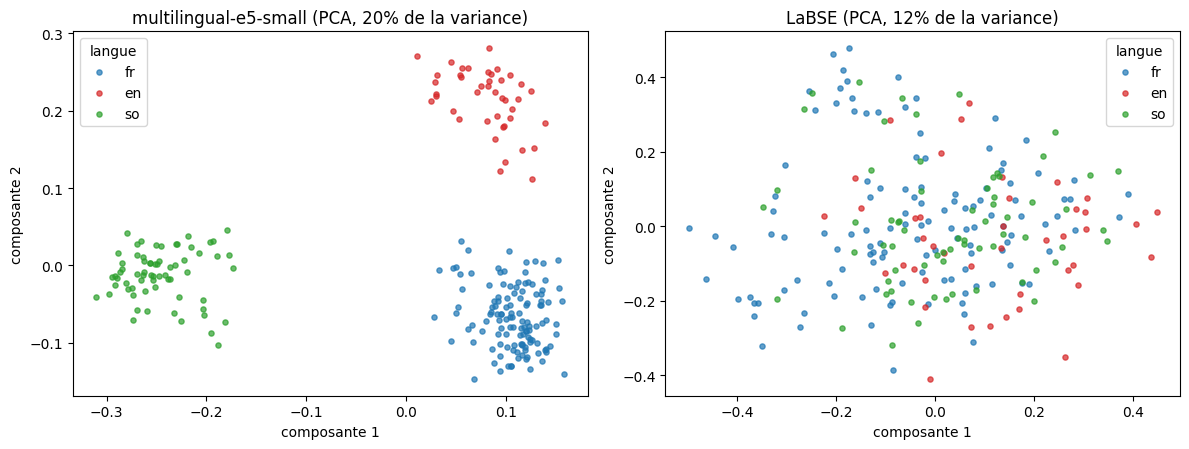

In [23]:
# Évaluation INTRINSÈQUE de l'espace vectoriel : l'espace regroupe-t-il par langue ou par sens ?
# (l'évaluation EXTRINSÈQUE, sur la tâche de recherche, est faite plus bas avec Hit@3 et MRR)
from sklearn.decomposition import PCA

if not MATRICES_EMB:
    print("Approche 2 inactive : cette cellule demande les embeddings (Colab).")
else:
    langues = passages["langue"].to_numpy()
    faits_passage = [set(f.split(";")) - {""} for f in passages["faits"]]
    n = len(passages)
    lignes_cos, lignes_voisins = [], []
    figures = {}
    for methode, E in MATRICES_EMB.items():
        E = E / np.linalg.norm(E, axis=1, keepdims=True)
        S = E @ E.T
        valeurs = {"même fait, autre langue": [], "faits différents, même langue": [], "faits différents, autre langue": []}
        for i in range(n):
            for j in range(i + 1, n):
                if not faits_passage[i] or not faits_passage[j]:
                    continue
                partage = bool(faits_passage[i] & faits_passage[j])
                if partage and langues[i] != langues[j]:
                    valeurs["même fait, autre langue"].append(S[i, j])
                elif not partage:
                    valeurs["faits différents, " + ("même langue" if langues[i] == langues[j] else "autre langue")].append(S[i, j])
        lignes_cos.append({"modèle": MODELES_EMB[methode]["nom"].split("/")[-1], **{k: round(float(np.mean(v)), 3) for k, v in valeurs.items()}})
        meme_langue, meme_fait = [], []
        for i in range(n):
            s = S[i].copy(); s[i] = -9
            top5 = np.argsort(-s)[:5]
            meme_langue.append(np.mean([langues[j] == langues[i] for j in top5]))
            if faits_passage[i]:
                meme_fait.append(np.mean([bool(faits_passage[i] & faits_passage[j]) for j in top5]))
        lignes_voisins.append({"modèle": MODELES_EMB[methode]["nom"].split("/")[-1],
                               "5 plus proches voisins dans la même langue": round(float(np.mean(meme_langue)), 2),
                               "5 plus proches voisins avec le même fait": round(float(np.mean(meme_fait)), 2)})
        figures[methode] = PCA(n_components=2).fit(E), E
    print("Cosinus moyen entre passages (plus c'est haut, plus les passages sont proches) :")
    print(pd.DataFrame(lignes_cos).set_index("modèle").to_string())
    print("\nVoisinage de chaque passage :")
    print(pd.DataFrame(lignes_voisins).set_index("modèle").to_string())

    # Projection PCA en 2D : à lire avec prudence, une carte 2D déforme un espace à 384 ou 768 dimensions
    fig, axes = plt.subplots(1, len(figures), figsize=(6 * len(figures), 4.6))
    axes = np.atleast_1d(axes)
    couleurs = {"fr": "#1f77b4", "en": "#d62728", "so": "#2ca02c"}
    for ax, (methode, (pca, E)) in zip(axes, figures.items()):
        xy = pca.transform(E)
        for langue, couleur in couleurs.items():
            masque = langues == langue
            ax.scatter(xy[masque, 0], xy[masque, 1], s=14, alpha=0.7, c=couleur, label=langue)
        ax.set_title(f"{MODELES_EMB[methode]['nom'].split('/')[-1]} (PCA, {pca.explained_variance_ratio_.sum():.0%} de la variance)")
        ax.set_xlabel("composante 1"); ax.set_ylabel("composante 2"); ax.legend(title="langue")
    plt.tight_layout()
    plt.show()

**Tokenizers.** Le somali est le plus fragmenté pour les deux modèles : **1,95 sous-mot par mot** pour e5 (1,49 en français, 1,28 en anglais) et **1,66** pour LaBSE (1,38 et 1,19). C'est un indice de couverture plus faible du somali, dans le sens de notre hypothèse sur les résultats en somali, mais **ce n'est pas une preuve** : LaBSE fragmente moins que e5 et il est pourtant moins bon en somali (section 8). Aucun passage ne dépasse la longueur maximale (133 éléments au plus, pour 256 ou 512 permis) : il n'y a pas de troncature.

**Espace vectoriel.** Les deux modèles ne rangent pas les passages de la même façon :
- **e5-small** regroupe par **langue**. 96 % des 5 plus proches voisins d'un passage sont dans sa langue, et un passage est aussi proche d'un passage de la même langue sur un autre sujet (cosinus 0,841) que de sa propre version dans une autre langue (0,837). Sur la figure, les trois langues forment trois groupes séparés.
- **LaBSE** regroupe par **sens**. Un même fait exprimé en deux langues a un cosinus de 0,786, contre 0,467 pour deux faits différents de la même langue. Sur la figure, les langues sont mélangées.

Cela explique les résultats de la section 8 : LaBSE est meilleur quand la réponse est dans une autre langue, e5-small quand elle est dans la langue de la question. **Prudence :** la PCA ne représente que 20 % (e5) et 12 % (LaBSE) de la variance. La figure illustre, ce sont les mesures chiffrées qui comptent.

### Approche 3 (facultative) : mélange de TF-IDF et d'un modèle d'embeddings

On normalise chaque score entre 0 et 1, puis on fait `alpha × TF-IDF + (1 − alpha) × embeddings`, pour chacun des deux modèles (méthodes `melange` et `melange_labse`). La valeur de `alpha` est choisie sur les requêtes `dev` uniquement.

In [24]:
def minmax(x):
    x = np.asarray(x, dtype=float)
    ecart = x.max() - x.min()
    return (x - x.min()) / ecart if ecart > 0 else np.zeros_like(x)


MELANGES = {"embeddings": "melange", "labse": "melange_labse"}    # méthode d'embeddings -> méthode de mélange
ALPHAS = {}

for methode_emb, nom_melange in MELANGES.items():
    if methode_emb not in FONCTIONS:
        continue
    melange = lambda q, a, se=FONCTIONS[methode_emb]: a * minmax(scores_tfidf(q)) + (1 - a) * minmax(se(q)) + 1e-9
    resultats_alpha = {a: resume(evaluer(lambda q, a=a: melange(q, a), dev))["MRR"] for a in [0.0, 0.25, 0.5, 0.75, 1.0]}
    ALPHAS[nom_melange] = max(resultats_alpha, key=resultats_alpha.get)
    FONCTIONS[nom_melange] = lambda q, a=ALPHAS[nom_melange], m=melange: m(q, a)
    print(f"{nom_melange} : MRR sur dev selon alpha", {a: round(float(v), 3) for a, v in resultats_alpha.items()},
          "-> alpha choisi :", ALPHAS[nom_melange])

if not ALPHAS:
    print("Mélange non calculé : l'approche 2 n'est pas active.")

melange : MRR sur dev selon alpha {0.0: 0.66, 0.25: 0.771, 0.5: 0.784, 0.75: 0.782, 1.0: 0.77} -> alpha choisi : 0.5
melange_labse : MRR sur dev selon alpha {0.0: 0.576, 0.25: 0.781, 0.5: 0.777, 0.75: 0.775, 1.0: 0.77} -> alpha choisi : 0.25


## 8. Protocole expérimental et résultats

- **Unité :** le passage.
- **Réglages :** sur `dev` uniquement (variante TF-IDF, `alpha`).
- **Résultat final :** sur `test` uniquement.
- **Métriques :**
  - **Precision@3** : part des 3 passages affichés qui sont pertinents.
  - **Hit@3** : 1 si au moins un bon passage est dans le top 3.
  - **MRR** : moyenne de 1/rang du premier bon passage (1 si en première position, 0,5 en deuxième...).
- **Deux scénarios** : `toutes_langues` et `meme_langue` (voir partie 4).

Avec peu de requêtes, un seul changement fait bouger les moyennes. On regarde donc aussi le détail par langue, par type et requête par requête.

In [25]:
detail = {(nom, sc): evaluer(f, requetes, sc) for nom, f in FONCTIONS.items() for sc in SCENARIOS}

tableaux = {}
for sc in SCENARIOS:
    tableaux[sc] = pd.concat(
        {nom: resume(detail[(nom, sc)].query("partition == 'test'")) for nom in FONCTIONS}, axis=1
    ).T
    print(f"Résultats sur les requêtes TEST - scénario {sc} (K = {K}) :")
    print(tableaux[sc].round(3), "\n")

Résultats sur les requêtes TEST - scénario toutes_langues (K = 3) :
                 P@k  Hit@k    MRR  requêtes
tfidf          0.270  0.794  0.708      63.0
embeddings     0.302  0.794  0.702      63.0
labse          0.286  0.571  0.523      63.0
melange        0.296  0.841  0.792      63.0
melange_labse  0.349  0.825  0.742      63.0 

Résultats sur les requêtes TEST - scénario meme_langue (K = 3) :
                 P@k  Hit@k    MRR  requêtes
tfidf          0.296  0.889  0.798      54.0
embeddings     0.278  0.815  0.751      54.0
labse          0.179  0.537  0.429      54.0
melange        0.321  0.944  0.890      54.0
melange_labse  0.302  0.889  0.794      54.0 



In [26]:
# Résultats par langue de la requête et par type (test)
for sc in SCENARIOS:
    for critere in ["langue", "type"]:
        t = pd.concat(
            {nom: detail[(nom, sc)].query("partition == 'test'").groupby(critere)[["Hit@k", "RR"]].mean()
             for nom in FONCTIONS}, axis=1
        )
        print(f"Scénario {sc} - par {critere} :")
        print(t.round(3), "\n")

Scénario toutes_langues - par langue :
        tfidf        embeddings         labse        melange        melange_labse       
        Hit@k     RR      Hit@k     RR  Hit@k     RR   Hit@k     RR         Hit@k     RR
langue                                                                                  
en      0.750  0.619      0.938  0.799  0.500  0.527   0.812  0.747         0.875  0.753
fr      0.727  0.680      0.818  0.747  0.727  0.584   0.818  0.775         0.818  0.774
so      0.880  0.789      0.680  0.601  0.480  0.466   0.880  0.835         0.800  0.707 

Scénario toutes_langues - par type :
              tfidf        embeddings         labse        melange        melange_labse       
              Hit@k     RR      Hit@k     RR  Hit@k     RR   Hit@k     RR         Hit@k     RR
type                                                                                          
court         0.714  0.631      0.714  0.714  0.429  0.545   0.714  0.665         0.857  0.671
mots_com

In [27]:
# Requêtes dont le fait n'existe pas dans leur langue : seule la recherche entre langues peut réussir
print("Requêtes croisées du TEST (scénario toutes_langues) :")
for nom in FONCTIONS:
    d = detail[(nom, "toutes_langues")]
    d = d[(d["partition"] == "test") & d["id"].isin(CROISEES)]
    print(f"  {nom:12s} Hit@k = {d['Hit@k'].mean():.2f}   MRR = {d['RR'].mean():.2f}   ({len(d)} requêtes)")

# Le premier résultat est-il dans la langue de la requête ?
print("\nPart des requêtes TEST dont le premier résultat est dans la langue de la requête :")
test_q = requetes[requetes["partition"] == "test"]
for nom, f in FONCTIONS.items():
    memes = []
    for _, r in test_q.iterrows():
        classement = classer(f(r["requete"]))
        if classement:
            memes.append(passages.iloc[classement[0]]["langue"] == r["langue"])
    print(f"  {nom:12s} {np.mean(memes):.2f}   (sur {len(memes)} requêtes qui ont au moins un résultat)")

Requêtes croisées du TEST (scénario toutes_langues) :
  tfidf        Hit@k = 0.22   MRR = 0.17   (9 requêtes)
  embeddings   Hit@k = 0.56   MRR = 0.36   (9 requêtes)
  labse        Hit@k = 0.44   MRR = 0.46   (9 requêtes)
  melange      Hit@k = 0.22   MRR = 0.20   (9 requêtes)
  melange_labse Hit@k = 0.44   MRR = 0.43   (9 requêtes)

Part des requêtes TEST dont le premier résultat est dans la langue de la requête :
  tfidf        0.97   (sur 63 requêtes qui ont au moins un résultat)
  embeddings   0.97   (sur 63 requêtes qui ont au moins un résultat)
  labse        0.48   (sur 63 requêtes qui ont au moins un résultat)
  melange      0.97   (sur 63 requêtes qui ont au moins un résultat)
  melange_labse 0.87   (sur 63 requêtes qui ont au moins un résultat)


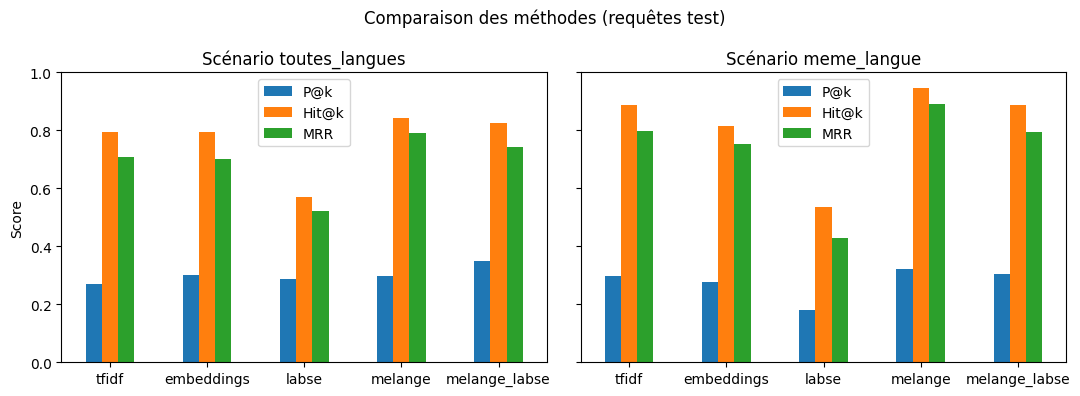

In [28]:
# Figure : comparaison des méthodes sur le test, un graphique par scénario
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, sc in zip(axes, SCENARIOS):
    tableaux[sc][["P@k", "Hit@k", "MRR"]].plot(kind="bar", ax=ax, rot=0)
    ax.set_title(f"Scénario {sc}")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Score")
plt.suptitle("Comparaison des méthodes (requêtes test)")
plt.tight_layout()
plt.show()

## 9. Analyse d'erreurs

On liste les requêtes **test** pour lesquelles le premier résultat n'est pas un bon passage (scénario `toutes_langues`) : soit le bon passage est plus bas dans la liste, soit il n'apparaît pas du tout. Il en faut au moins 10 en tout pour le rapport (erreurs ou cas difficiles). On regarde en particulier si un même passage revient en premier pour des requêtes sans rapport (passage « attracteur »).

Pour chaque cas, on note une **cause possible**, écrite à la main après lecture du premier résultat. La colonne `cause_possible` est remplie à partir du dictionnaire `CAUSES` ci-dessous. Causes à utiliser : `synonyme / paraphrase`, `autre langue`, `abréviation`, `faute ou accents`, `requête trop courte`, `faits voisins`, `information absente du corpus`, `mauvaise annotation`, `langue peu couverte par le modèle`.

In [29]:
# Causes notées à la main après lecture du premier résultat de chaque cas (exécutions Colab du 21/11/2026).
# À réviser si le corpus ou les requêtes changent.
CAUSES = {
    "tfidf": {
        "Q08": "paraphrase : « plus d'argent » n'a aucun mot commun avec « difficulté financière » et « étalement » ; « scolarité » ramène l'attestation de scolarité",
        "Q10": "faits voisins : « repasser » ramène l'article sur la capitalisation des crédits (UE à repasser) avant les sessions de rattrapage",
        "Q12": "faits voisins : « note » et « examen » ramènent le contrôle des connaissances avant les réclamations",
        "Q15": "autre langue : le fait n'existe qu'en somali ; les seuls mots communs (« pour », « université ») ramènent le préambule de la charte informatique",
        "Q16": "autre langue : le fait n'existe qu'en anglais ; « trouver » et « étudiant » ramènent la recherche de stage",
        "Q17": "autre langue : le fait n'existe qu'en anglais et en somali ; « bibliotheque » ramène la carte d'étudiant, qui cite la bibliothèque",
        "Q24": "faits voisins : « exam » et « grade » ramènent le passage sur les notes avant celui sur les appels",
        "Q27": "faits voisins : « borrowed » ressemble à « Borrowing » (n-grammes de caractères), donc l'emprunt passe avant le renouvellement",
        "Q28": "paraphrase : « afford » ne rencontre pas « financial hardship » ; « tuition » ramène le paiement des frais",
        "Q30": "paraphrase : « skip » n'est pas « unexcused absences » ; seul le mot « before » est commun avec le passage sur les stages",
        "Q31": "paraphrase : aucun mot utile en commun (« and », « should ») ; le passage sur la langue d'enseignement arrive devant celui sur le certificat médical",
        "Q32": "paraphrase : « second chance » ne ressemble pas à « resit » ; « second » ramène le « second instalment » du paiement",
        "Q37": "autre langue : le fait n'existe qu'en français ; « degree » ramène le passage sur le visa (« foreign degree »)",
        "Q39": "autre langue : le fait n'existe qu'en français ; « dates » ramène le préambule du calendrier",
        "Q47": "faits voisins : « waxbarashada » ramène le passage somali sur le remboursement des frais avant celui sur les difficultés financières",
        "Q52": "autre langue : la réponse est en français et en anglais ; « tababar » ramène le passage somali sur la convention de stage",
        "Q53": "autre langue : la réponse est en français et en anglais ; « waxbarasho » ressemble à « waxbarashada » et ramène le premier article du règlement somali",
        "Q56": "mauvaise annotation (possible) : le passage somali sur le remboursement parle des étudiants étrangers et du refus de visa ; ce premier résultat est défendable",
        "Q58": "faits voisins : « crédits » ramène la capitalisation des crédits avant les conditions de passage en Master 2",
        "Q59": "faits voisins : « examen » ramène l'assiduité (absences) avant l'absence à un examen",
        "Q62": "paraphrase : « durée » ne ressemble pas à « vingt minutes » ; « soutenance » et « mémoire » ramènent les dates des soutenances",
        "Q66": "faits voisins : « library » et « book » ramènent le prêt entre bibliothèques avant les livres perdus",
        "Q71": "faits voisins : le passage somali sur les frais de scolarité arrive avant celui sur le retard de paiement",
        "Q76": "paraphrase : « waxbarashadayda » ressemble à « waxbarashada » et ramène le passage sur les frais avant celui sur la suspension des études",
        "Q77": "faits voisins : le passage somali sur le remboursement des frais arrive avant celui sur le paiement fait deux fois"
    },
    "embeddings": {
        "Q03": "faits voisins : l'article sur l'erreur ou le double paiement passe avant celui sur les modalités de paiement",
        "Q08": "faits voisins : l'attestation de scolarité arrive en premier (même thème, autre fait) ; le fait « étalement » est 17e",
        "Q10": "faits voisins : l'article sur l'absence à un examen passe avant les sessions de rattrapage",
        "Q15": "passage attracteur : le préambule du guide d'inscription arrive en premier pour une question sur le bus ; le bon passage (somali) est 2e",
        "Q16": "autre langue : le fait n'existe qu'en anglais ; le premier résultat est un passage de contacts sans rapport",
        "Q17": "faits voisins : les horaires de la scolarité passent avant ceux de la bibliothèque",
        "Q18": "faits voisins : l'article sur l'erreur de paiement passe avant celui sur le reçu (requête courte)",
        "Q32": "faits voisins : l'article sur l'exclusion après des échecs répétés passe avant celui sur le rattrapage",
        "Q33": "faits voisins : le passage sur la connexion à la plateforme passe avant celui sur le compte verrouillé",
        "Q36": "autre langue : le fait n'existe qu'en français ; le premier résultat est le passage anglais sur les appels de notes",
        "Q37": "autre langue : le fait n'existe qu'en français ; le premier résultat est le passage anglais sur l'inscription",
        "Q39": "faits voisins : les sessions de rattrapage (anglais) passent avant les dates d'examens du semestre 1 (français)",
        "Q41": "faits voisins : le passage somali sur le paiement fait deux fois passe avant celui sur les modalités de paiement",
        "Q42": "faits voisins : la réinscription (somali) arrive avant l'attestation de scolarité ; le bon passage est 3e",
        "Q46": "passage attracteur : « Habka imtixaanka » (déroulement des examens) arrive en premier pour une question sur les absences en cours ; le bon passage est 8e",
        "Q47": "faits voisins : le passage somali sur ce que comprennent les droits arrive en premier ; le fait « étalement » est 60e",
        "Q51": "faits voisins : le passage somali sur le dépôt des devoirs (plateforme) passe avant celui sur le compte verrouillé",
        "Q52": "autre langue : la réponse est en français et en anglais ; le premier résultat est le passage somali voisin sur la convention de stage (36e rang pour le bon passage)",
        "Q53": "autre langue : la réponse est en français et en anglais ; le premier résultat est l'attestation de scolarité, qui cite le dossier de bourse (145e rang pour le bon passage)",
        "Q62": "faits voisins : les dates des soutenances passent avant la durée de la soutenance",
        "Q70": "passage attracteur : « Habka imtixaanka » arrive en premier pour une question sur le changement d'adresse, sans rapport",
        "Q72": "faits voisins : « Habka imtixaanka » (arriver en retard à l'examen) passe avant le retard en cours",
        "Q73": "faits voisins : « Habka imtixaanka » (déroulement de l'examen) passe avant l'absence à un examen",
        "Q74": "faits voisins : « Habka imtixaanka » passe avant les aménagements pour les étudiants en situation de handicap ; le bon passage est 16e",
        "Q80": "faits voisins : le passage somali sur ce que comprennent les droits (accès aux salles informatiques) passe avant celui sur les logiciels gratuits",
        "Q82": "passage attracteur : « Lumitaanka ama dhaawaca buugga » (livre perdu) arrive en premier pour une question sur le diplôme ; le bon passage est 6e"
    },
    "labse": {
        "Q02": "passage attracteur : le préambule du règlement somali arrive en premier pour une question sur le montant des frais ; le bon passage est 3e",
        "Q03": "faits voisins : le passage somali sur le paiement fait deux fois passe avant les modalités de paiement",
        "Q05": "faits voisins : l'article sur les sessions d'examen passe avant les dates d'examens du semestre 1",
        "Q06": "passage attracteur : le plan du mémoire arrive en premier pour une question sur la note finale",
        "Q08": "faits voisins : l'article sur le retard de paiement arrive en premier (même thème, autre fait) ; le fait « étalement » est 37e",
        "Q10": "faits voisins : l'article sur la capitalisation des crédits passe avant les sessions de rattrapage",
        "Q12": "faits voisins : l'article sur la fraude et le plagiat passe avant celui sur les réclamations (règles des examens)",
        "Q15": "passage attracteur : la présentation du responsable de la formation arrive en premier pour une question sur le bus ; le bon passage (somali) est 2e",
        "Q16": "passage attracteur : la poursuite d'études arrive en premier pour une question sur le logement (le fait n'existe qu'en anglais)",
        "Q18": "faits voisins : l'article sur l'erreur ou le double paiement passe avant celui sur le reçu (requête courte)",
        "Q20": "passage attracteur : le premier article du règlement somali arrive en premier pour une requête courte sur la durée du stage",
        "Q23": "faits voisins : le passage somali sur le paiement fait deux fois passe avant les modalités de paiement",
        "Q24": "passage attracteur : le passage somali sur le retard de paiement arrive en premier pour une question sur la contestation d'une note ; le bon passage est 6e",
        "Q28": "faits voisins : le passage somali sur le retard de paiement arrive en premier ; le fait « étalement » est 97e",
        "Q30": "faits voisins : le passage somali sur le retard en cours (trois retards = une absence) passe avant celui sur les absences ; le bon passage est 15e",
        "Q31": "passage attracteur : le passage sur le transfert et les équivalences arrive en premier pour une question sur la maladie ; le bon passage est 20e",
        "Q32": "faits voisins : l'article sur l'exclusion après des échecs répétés passe avant celui sur le rattrapage",
        "Q37": "passage attracteur : le préambule du guide des stages arrive en premier pour une question sur la mention du diplôme (le fait n'existe qu'en français)",
        "Q39": "faits voisins : le passage somali sur les examens et le rattrapage passe avant les dates d'examens du semestre 1 (français)",
        "Q41": "faits voisins : le passage sur le semestre 2 (date du second versement) arrive avant les modalités de paiement",
        "Q42": "faits voisins : le passage sur le dossier d'inscription arrive en premier pour une question sur l'attestation de scolarité",
        "Q45": "passage attracteur : le passage sur la candidature en Master arrive en premier pour une question sur le bus ; le bon passage est 84e",
        "Q46": "passage attracteur : le passage somali sur la maktabadda (bibliothèque) arrive en premier pour une question sur les absences",
        "Q47": "faits voisins : le passage somali sur ce que comprennent les droits arrive en premier ; le fait « étalement » est 64e",
        "Q48": "passage attracteur : le passage sur ce que comprennent les droits arrive en premier pour une question sur la maladie",
        "Q50": "faits voisins : le passage sur le Master 2 arrive en premier pour une question sur le passage en année supérieure",
        "Q52": "faits voisins : le passage sur le lieu du stage arrive avant ceux sur la recherche de stage ; le bon passage est 18e",
        "Q53": "faits voisins : le passage somali sur les frais de scolarité arrive en premier pour une question sur les bourses ; le bon passage est 32e",
        "Q55": "faits voisins : le passage somali sur le paiement fait deux fois (qui parle de deux reçus) passe avant celui sur le reçu",
        "Q61": "faits voisins : les modalités de paiement passent avant le virement bancaire",
        "Q62": "faits voisins : l'article sur la durée du stage arrive en premier pour la durée de la soutenance ; le bon passage est 36e",
        "Q68": "passage attracteur : la poursuite d'études arrive en premier pour une question sur le médecin du campus (le fait n'existe qu'en anglais)",
        "Q69": "faits voisins : les horaires de la bibliothèque (anglais) arrivent en premier pour les horaires de la cafétéria (makhaayad)",
        "Q71": "passage attracteur : l'article sur les sanctions informatiques arrive en premier pour une question sur le retard de paiement",
        "Q74": "faits voisins : l'article sur le contrôle continu passe avant les aménagements d'examen pour les étudiants en situation de handicap",
        "Q79": "faits voisins : le passage sur le mot de passe oublié passe avant celui sur les règles de choix du mot de passe ; le bon passage est 21e",
        "Q81": "passage attracteur : le passage sur le Master 2 arrive en premier pour une question sur la salle de prière (fait uniquement somali)",
        "Q82": "faits voisins : l'article sur le jury et les délibérations passe avant celui sur le relevé de notes et le diplôme"
    }
}


def cas_difficiles(nom, scenario="toutes_langues"):
    d = detail[(nom, scenario)]
    d = d[(d["partition"] == "test") & (d["rang"].isna() | (d["rang"] > 1))]
    lignes = []
    for _, r in d.iterrows():
        req = requetes[requetes["id"] == r["id"]].iloc[0]
        classement = classer(FONCTIONS[nom](req["requete"]))
        if classement:
            p = passages.iloc[classement[0]]
            top1 = f'{p["id"]} : {p["titre"][:45]}'
        else:
            top1 = "(aucun résultat)"
        langues_attendues = sorted(passages.loc[passages["id"].isin(req["attendus_toutes"]), "langue"].unique())
        lignes.append({
            "id": r["id"], "requete": req["requete"], "langue": r["langue"], "type": r["type"],
            "fait_attendu": f'{req["faits"]} ({",".join(langues_attendues)})',
            "rang_du_bon_passage": "absent" if pd.isna(r["rang"]) else int(r["rang"]),
            "premier_résultat": top1, "cause_possible": CAUSES.get(nom, {}).get(r["id"], ""),
        })
    return pd.DataFrame(lignes)


erreurs_tfidf = cas_difficiles("tfidf")
print("Cas difficiles de la baseline TF-IDF :", len(erreurs_tfidf))
erreurs_tfidf

Cas difficiles de la baseline TF-IDF : 25


,id,requete,langue,type,fait_attendu,rang_du_bon_passage,premier_résultat,cause_possible
0,Q08,"Je n'ai plus d'argent pour payer ma scolarité,...",fr,paraphrase,"etalement (en,fr,so)",41,guide_inscription_fr-15 : 14. Attestation de s...,paraphrase : « plus d'argent » n'a aucun mot c...
1,Q10,Puis-je repasser un examen que j'ai raté ?,fr,paraphrase,"rattrapage (en,fr,so)",2,reglement_etudes_fr-17 : Article 16 – Capitali...,faits voisins : « repasser » ramène l'article ...
2,Q12,Comment contester ma note d'examen ?,fr,paraphrase,"reclamation_note (en,fr)",4,reglement_etudes_fr-08 : Article 7 – Contrôle ...,faits voisins : « note » et « examen » ramènen...
3,Q15,Y a-t-il un bus pour aller à l'université ?,fr,paraphrase,transport_bus (so),196,charte_informatique_fr-01 : CHARTE D'UTILISATI...,autre langue : le fait n'existe qu'en somali ;...
4,Q16,Où trouver un logement étudiant ?,fr,paraphrase,logement (en),132,guide_stage_memoire_fr-04 : 3. Recherche d'un ...,autre langue : le fait n'existe qu'en anglais ...
5,Q17,bibliotheque horaires,fr,court,"horaires_bibliotheque (en,so)",66,guide_inscription_fr-14 : 13. Carte d'étudiant,autre langue : le fait n'existe qu'en anglais ...
6,Q24,How do I appeal an exam grade?,en,mots_communs,"reclamation_note (en,fr)",2,student_handbook_en-20 : 19. Grades,faits voisins : « exam » et « grade » ramènent...
7,Q27,Can I renew a borrowed book?,en,mots_communs,"renouvellement (en,so)",2,library_rules_en-04 : 3. Borrowing,faits voisins : « borrowed » ressemble à « Bor...
8,Q28,"I cannot afford my tuition at the moment, what...",en,paraphrase,"etalement (en,fr,so)",41,student_handbook_en-08 : 7. Tuition and payment,paraphrase : « afford » ne rencontre pas « fin...
9,Q30,How many classes can I skip before getting a w...,en,paraphrase,"absences (en,fr,so)",4,student_handbook_en-25 : 24. Internships,paraphrase : « skip » n'est pas « unexcused ab...


In [30]:
# Même tableau pour chaque modèle d'embeddings (si l'approche 2 est active)
erreurs = {}
for nom_methode in ["embeddings", "labse"]:
    if nom_methode in FONCTIONS:
        erreurs[nom_methode] = cas_difficiles(nom_methode)
        print(f"Cas difficiles de la méthode {nom_methode} :", len(erreurs[nom_methode]))
        display(erreurs[nom_methode])
if not erreurs:
    print("Approche 2 non active : pas de tableau d'erreurs pour les embeddings.")

Cas difficiles de la méthode embeddings : 26


,id,requete,langue,type,fait_attendu,rang_du_bon_passage,premier_résultat,cause_possible
0,Q03,Peut-on payer les frais de scolarité en deux v...,fr,mots_communs,"paiement_modalites (en,fr,so)",3,frais_bourses_fr-10 : 9. Erreur ou double paie...,faits voisins : l'article sur l'erreur ou le d...
1,Q08,"Je n'ai plus d'argent pour payer ma scolarité,...",fr,paraphrase,"etalement (en,fr,so)",17,guide_inscription_fr-15 : 14. Attestation de s...,faits voisins : l'attestation de scolarité arr...
2,Q10,Puis-je repasser un examen que j'ai raté ?,fr,paraphrase,"rattrapage (en,fr,so)",5,reglement_etudes_fr-13 : Article 12 – Absence ...,faits voisins : l'article sur l'absence à un e...
3,Q15,Y a-t-il un bus pour aller à l'université ?,fr,paraphrase,transport_bus (so),2,guide_inscription_fr-01 : GUIDE D'INSCRIPTION ...,passage attracteur : le préambule du guide d'i...
4,Q16,Où trouver un logement étudiant ?,fr,paraphrase,logement (en),2,frais_bourses_fr-16 : 15. Contacts,autre langue : le fait n'existe qu'en anglais ...
5,Q17,bibliotheque horaires,fr,court,"horaires_bibliotheque (en,so)",4,guide_inscription_fr-03 : 2. Lieu et horaires ...,faits voisins : les horaires de la scolarité p...
6,Q18,recu paiement,fr,court,"recu_paiement (en,fr,so)",4,frais_bourses_fr-10 : 9. Erreur ou double paie...,faits voisins : l'article sur l'erreur de paie...
7,Q32,Is there a second chance if I fail a course?,en,paraphrase,"rattrapage (en,fr,so)",3,reglement_etudes_fr-22 : Article 21 – Exclusio...,faits voisins : l'article sur l'exclusion aprè...
8,Q33,I can't log in anymore after several attempts,en,paraphrase,"compte_bloque (en,fr,so)",2,student_handbook_en-22 : 21. Learning platform,faits voisins : le passage sur la connexion à ...
9,Q36,What is the penalty for plagiarism in a report?,en,paraphrase,fraude;plagiat_memoire (fr),3,student_handbook_en-21 : 20. Appeals,autre langue : le fait n'existe qu'en français...


Cas difficiles de la méthode labse : 38


,id,requete,langue,type,fait_attendu,rang_du_bon_passage,premier_résultat,cause_possible
0,Q02,Combien coûtent les frais de scolarité en Mast...,fr,mots_communs,"montant_frais (en,fr,so)",3,xeerka_waxbarashada_so-01 : XEERKA WAXBARASHAD...,passage attracteur : le préambule du règlement...
1,Q03,Peut-on payer les frais de scolarité en deux v...,fr,mots_communs,"paiement_modalites (en,fr,so)",2,lacagaha_iyo_caawimaadda_so-03 : 2. Bixin khal...,faits voisins : le passage somali sur le paiem...
2,Q05,Quelles sont les dates des examens du premier ...,fr,mots_communs,dates_examens_s1 (fr),2,reglement_etudes_fr-10 : Article 9 – Sessions ...,faits voisins : l'article sur les sessions d'e...
3,Q06,Comment est calculée la note finale d'un module ?,fr,mots_communs,"note_finale (en,fr)",3,guide_stage_memoire_fr-12 : 11. Plan du mémoire,passage attracteur : le plan du mémoire arrive...
4,Q08,"Je n'ai plus d'argent pour payer ma scolarité,...",fr,paraphrase,"etalement (en,fr,so)",37,frais_bourses_fr-07 : 6. Retard de paiement,faits voisins : l'article sur le retard de pai...
5,Q10,Puis-je repasser un examen que j'ai raté ?,fr,paraphrase,"rattrapage (en,fr,so)",8,reglement_etudes_fr-17 : Article 16 – Capitali...,faits voisins : l'article sur la capitalisatio...
6,Q12,Comment contester ma note d'examen ?,fr,paraphrase,"reclamation_note (en,fr)",2,reglement_etudes_fr-14 : Article 13 – Fraude e...,faits voisins : l'article sur la fraude et le ...
7,Q15,Y a-t-il un bus pour aller à l'université ?,fr,paraphrase,transport_bus (so),2,syllabus_master_iamd_fr-16 : 15. Responsable d...,passage attracteur : la présentation du respon...
8,Q16,Où trouver un logement étudiant ?,fr,paraphrase,logement (en),7,syllabus_master_iamd_fr-18 : 17. Poursuite d'é...,passage attracteur : la poursuite d'études arr...
9,Q18,recu paiement,fr,court,"recu_paiement (en,fr,so)",5,frais_bourses_fr-10 : 9. Erreur ou double paie...,faits voisins : l'article sur l'erreur ou le d...


### Causes des cas difficiles

Lecture à la main des tableaux ci-dessus (scénario `toutes_langues`, requêtes test). Un « cas difficile » est une requête dont le premier résultat n'est pas un bon passage. Le rang est celui du premier bon passage. La colonne `cause_possible` du tableau LaBSE était encore vide lors de l'exécution sur Colab : les causes sont donc données ici, pour les trois méthodes.

**Causes principales**
- `paraphrase` : la requête et le passage n'ont presque aucun mot en commun.
- `autre langue` : le bon passage n'existe pas dans la langue de la requête.
- `faits voisins` : un passage proche par le sujet, mais qui répond à une autre question, passe devant.
- `passage attracteur` : un passage sans rapport avec la question arrive en premier, et le même passage revient pour plusieurs requêtes.
- `langue peu couverte` : le modèle semble mal représenter le somali.
- `mauvaise annotation (possible)` : le premier résultat est défendable.

| Cause principale | TF-IDF | e5-small | LaBSE |
|---|---|---|---|
| autre langue | 7 | 5 | 0 |
| faits voisins | 10 | 17 | 24 |
| mauvaise annotation (possible) | 1 | 0 | 0 |
| paraphrase | 7 | 0 | 0 |
| passage attracteur | 0 | 4 | 14 |
| **Total** | **25** | **26** | **38** |

### Causes des cas difficiles – Baseline TF-IDF (25 cas)

| Requête | Langue | Bon passage (rang) | Premier résultat | Cause |
|---|---|---|---|---|
| Q08 Je n'ai plus d'argent pour payer ma scolarité, que faire ? | fr | etalement (rang 41) | guide_inscription_fr-15 : 14. Attestation de scolarité | **paraphrase** : « plus d'argent » n'a aucun mot commun avec « difficulté financière » et « étalement » ; « scolarité » ramène l'attestation de scolarité |
| Q10 Puis-je repasser un examen que j'ai raté ? | fr | rattrapage (rang 2) | reglement_etudes_fr-17 : Article 16 – Capitalisation des crédits | **faits voisins** : « repasser » ramène l'article sur la capitalisation des crédits (UE à repasser) avant les sessions de rattrapage |
| Q12 Comment contester ma note d'examen ? | fr | reclamation_note (rang 4) | reglement_etudes_fr-08 : Article 7 – Contrôle des connaissances | **faits voisins** : « note » et « examen » ramènent le contrôle des connaissances avant les réclamations |
| Q15 Y a-t-il un bus pour aller à l'université ? | fr | transport_bus (rang 196) | charte_informatique_fr-01 : CHARTE D'UTILISATION DE LA PLATEFORME PÉDAGOGIQUE ET DES RESSOURCES INFORMATIQUES | **autre langue** : le fait n'existe qu'en somali ; les seuls mots communs (« pour », « université ») ramènent le préambule de la charte informatique |
| Q16 Où trouver un logement étudiant ? | fr | logement (rang 132) | guide_stage_memoire_fr-04 : 3. Recherche d'un stage | **autre langue** : le fait n'existe qu'en anglais ; « trouver » et « étudiant » ramènent la recherche de stage |
| Q17 bibliotheque horaires | fr | horaires_bibliotheque (rang 66) | guide_inscription_fr-14 : 13. Carte d'étudiant | **autre langue** : le fait n'existe qu'en anglais et en somali ; « bibliotheque » ramène la carte d'étudiant, qui cite la bibliothèque |
| Q24 How do I appeal an exam grade? | en | reclamation_note (rang 2) | student_handbook_en-20 : 19. Grades | **faits voisins** : « exam » et « grade » ramènent le passage sur les notes avant celui sur les appels |
| Q27 Can I renew a borrowed book? | en | renouvellement (rang 2) | library_rules_en-04 : 3. Borrowing | **faits voisins** : « borrowed » ressemble à « Borrowing » (n-grammes de caractères), donc l'emprunt passe avant le renouvellement |
| Q28 I cannot afford my tuition at the moment, what are my options? | en | etalement (rang 41) | student_handbook_en-08 : 7. Tuition and payment | **paraphrase** : « afford » ne rencontre pas « financial hardship » ; « tuition » ramène le paiement des frais |
| Q30 How many classes can I skip before getting a warning? | en | absences (rang 4) | student_handbook_en-25 : 24. Internships | **paraphrase** : « skip » n'est pas « unexcused absences » ; seul le mot « before » est commun avec le passage sur les stages |
| Q31 I was sick and missed class, what should I bring? | en | certificat_medical (rang 2) | student_handbook_en-15 : 14. Language of instruction | **paraphrase** : aucun mot utile en commun (« and », « should ») ; le passage sur la langue d'enseignement arrive devant celui sur le certificat médical |
| Q32 Is there a second chance if I fail a course? | en | rattrapage (rang 2) | student_handbook_en-08 : 7. Tuition and payment | **paraphrase** : « second chance » ne ressemble pas à « resit » ; « second » ramène le « second instalment » du paiement |
| Q37 How is my final degree classified? | en | mentions (rang 16) | student_handbook_en-04 : 3. Visa and residence | **autre langue** : le fait n'existe qu'en français ; « degree » ramène le passage sur le visa (« foreign degree ») |
| Q39 exam dates | en | dates_examens_s1 (rang 15) | calendrier_universitaire_fr-01 : CALENDRIER UNIVERSITAIRE 2026-2027 | **autre langue** : le fait n'existe qu'en français ; « dates » ramène le préambule du calendrier |
| Q47 Lacag uma haysto waxbarashada, maxaan sameeyaa? | so | etalement (rang 35) | macluumaad_kooban_so-04 : Soo celinta lacagta waxbarashada | **faits voisins** : « waxbarashada » ramène le passage somali sur le remboursement des frais avant celui sur les difficultés financières |
| Q52 Yaa i caawin kara inaan helo tababar shaqo? | so | recherche_stage (rang 75) | guide_ardayga_so-17 : 16. Tababarka shaqada | **autre langue** : la réponse est en français et en anglais ; « tababar » ramène le passage somali sur la convention de stage |
| Q53 Sideen u codsadaa deeq waxbarasho? | so | bourse (rang 120) | xeerka_waxbarashada_so-02 : Qodobka 1 – Habaynta waxbarashada | **autre langue** : la réponse est en français et en anglais ; « waxbarasho » ressemble à « waxbarashada » et ramène le premier article du règlement somali |
| Q56 visa arday shisheeye | so | etudiants_etrangers (rang 3) | macluumaad_kooban_so-04 : Soo celinta lacagta waxbarashada | **mauvaise annotation (possible)** : le passage somali sur le remboursement parle des étudiants étrangers et du refus de visa ; ce premier résultat est défendable |
| Q58 Combien de crédits faut-il pour passer en Master 2 ? | fr | passage_annee (rang 2) | reglement_etudes_fr-17 : Article 16 – Capitalisation des crédits | **faits voisins** : « crédits » ramène la capitalisation des crédits avant les conditions de passage en Master 2 |
| Q59 Que faire si j'ai été absent à un examen ? | fr | absence_examen (rang 2) | reglement_etudes_fr-05 : Article 4 – Assiduité | **faits voisins** : « examen » ramène l'assiduité (absences) avant l'absence à un examen |
| Q62 Quelle est la durée d'une soutenance de mémoire ? | fr | soutenance (rang 6) | calendrier_universitaire_fr-11 : Soutenances de mémoire | **paraphrase** : « durée » ne ressemble pas à « vingt minutes » ; « soutenance » et « mémoire » ramènent les dates des soutenances |
| Q66 What happens if I lose a library book? | en | livre_perdu (rang 2) | library_rules_en-13 : 12. Interlibrary loan | **faits voisins** : « library » et « book » ramènent le prêt entre bibliothèques avant les livres perdus |
| Q71 Haddii aan lacagta ka daahiyo maxaa dhacaya? | so | retard_paiement (rang 2) | guide_ardayga_so-05 : 4. Lacagta waxbarashada | **faits voisins** : le passage somali sur les frais de scolarité arrive avant celui sur le retard de paiement |
| Q76 Ma joojin karaa waxbarashadayda hal sannad? | so | suspension_etudes (rang 2) | guide_ardayga_so-05 : 4. Lacagta waxbarashada | **paraphrase** : « waxbarashadayda » ressemble à « waxbarashada » et ramène le passage sur les frais avant celui sur la suspension des études |
| Q77 Lacagta waxbarashada laba jeer ayaan bixiyay, sideen u soo celiyaa? | so | erreur_paiement (rang 3) | macluumaad_kooban_so-04 : Soo celinta lacagta waxbarashada | **faits voisins** : le passage somali sur le remboursement des frais arrive avant celui sur le paiement fait deux fois |

### Causes des cas difficiles – Embeddings multilingual-e5-small (26 cas)

| Requête | Langue | Bon passage (rang) | Premier résultat | Cause |
|---|---|---|---|---|
| Q03 Peut-on payer les frais de scolarité en deux versements ? | fr | paiement_modalites (rang 3) | frais_bourses_fr-10 : 9. Erreur ou double paiement | **faits voisins** : l'article sur l'erreur ou le double paiement passe avant celui sur les modalités de paiement |
| Q08 Je n'ai plus d'argent pour payer ma scolarité, que faire ? | fr | etalement (rang 17) | guide_inscription_fr-15 : 14. Attestation de scolarité | **faits voisins** : l'attestation de scolarité arrive en premier (même thème, autre fait) ; le fait « étalement » est 17e |
| Q10 Puis-je repasser un examen que j'ai raté ? | fr | rattrapage (rang 5) | reglement_etudes_fr-13 : Article 12 – Absence à un examen | **faits voisins** : l'article sur l'absence à un examen passe avant les sessions de rattrapage |
| Q15 Y a-t-il un bus pour aller à l'université ? | fr | transport_bus (rang 2) | guide_inscription_fr-01 : GUIDE D'INSCRIPTION ET DE RÉINSCRIPTION – ANNÉE UNIVERSITAIRE 2026-2027 | **passage attracteur** : le préambule du guide d'inscription arrive en premier pour une question sur le bus ; le bon passage (somali) est 2e |
| Q16 Où trouver un logement étudiant ? | fr | logement (rang 2) | frais_bourses_fr-16 : 15. Contacts | **autre langue** : le fait n'existe qu'en anglais ; le premier résultat est un passage de contacts sans rapport |
| Q17 bibliotheque horaires | fr | horaires_bibliotheque (rang 4) | guide_inscription_fr-03 : 2. Lieu et horaires de la scolarité | **faits voisins** : les horaires de la scolarité passent avant ceux de la bibliothèque |
| Q18 recu paiement | fr | recu_paiement (rang 4) | frais_bourses_fr-10 : 9. Erreur ou double paiement | **faits voisins** : l'article sur l'erreur de paiement passe avant celui sur le reçu (requête courte) |
| Q32 Is there a second chance if I fail a course? | en | rattrapage (rang 3) | reglement_etudes_fr-22 : Article 21 – Exclusion pour résultats insuffisants | **faits voisins** : l'article sur l'exclusion après des échecs répétés passe avant celui sur le rattrapage |
| Q33 I can't log in anymore after several attempts | en | compte_bloque (rang 2) | student_handbook_en-22 : 21. Learning platform | **faits voisins** : le passage sur la connexion à la plateforme passe avant celui sur le compte verrouillé |
| Q36 What is the penalty for plagiarism in a report? | en | fraude;plagiat_memoire (rang 3) | student_handbook_en-21 : 20. Appeals | **autre langue** : le fait n'existe qu'en français ; le premier résultat est le passage anglais sur les appels de notes |
| Q37 How is my final degree classified? | en | mentions (rang 8) | student_handbook_en-02 : 1. Registration | **autre langue** : le fait n'existe qu'en français ; le premier résultat est le passage anglais sur l'inscription |
| Q39 exam dates | en | dates_examens_s1 (rang 2) | student_handbook_en-18 : 17. Exams and resits | **faits voisins** : les sessions de rattrapage (anglais) passent avant les dates d'examens du semestre 1 (français) |
| Q41 Sideen u bixiyaa lacagta waxbarashada laba qaybood? | so | paiement_modalites (rang 3) | lacagaha_iyo_caawimaadda_so-03 : 2. Bixin khalad ah ama laba jeer | **faits voisins** : le passage somali sur le paiement fait deux fois passe avant celui sur les modalités de paiement |
| Q42 Sidee u helaa warqadda caddeynta ardaynimada? | so | attestation_scolarite (rang 3) | guide_ardayga_so-04 : 3. Dib-u-diiwaangelinta | **faits voisins** : la réinscription (somali) arrive avant l'attestation de scolarité ; le bon passage est 3e |
| Q46 Imisa jeer ayaan casharka ka maqnaan karaa? | so | absences (rang 8) | guide_ardayga_so-11 : 10. Habka imtixaanka | **passage attracteur** : « Habka imtixaanka » (déroulement des examens) arrive en premier pour une question sur les absences en cours ; le bon passage est 8e |
| Q47 Lacag uma haysto waxbarashada, maxaan sameeyaa? | so | etalement (rang 60) | lacagaha_iyo_caawimaadda_so-04 : 3. Waxa lacagtu ku jirto | **faits voisins** : le passage somali sur ce que comprennent les droits arrive en premier ; le fait « étalement » est 60e |
| Q51 Akoonkayga waa la xiray, yaa furi kara? | so | compte_bloque (rang 2) | macluumaad_kooban_so-11 : Dhiibista shaqooyinka | **faits voisins** : le passage somali sur le dépôt des devoirs (plateforme) passe avant celui sur le compte verrouillé |
| Q52 Yaa i caawin kara inaan helo tababar shaqo? | so | recherche_stage (rang 36) | guide_ardayga_so-17 : 16. Tababarka shaqada | **autre langue** : la réponse est en français et en anglais ; le premier résultat est le passage somali voisin sur la convention de stage (36e rang pour le bon passage) |
| Q53 Sideen u codsadaa deeq waxbarasho? | so | bourse (rang 145) | guide_ardayga_so-16 : 15. Warqadda caddeynta ardaynimada | **autre langue** : la réponse est en français et en anglais ; le premier résultat est l'attestation de scolarité, qui cite le dossier de bourse (145e rang pour le bon passage) |
| Q62 Quelle est la durée d'une soutenance de mémoire ? | fr | soutenance (rang 3) | calendrier_universitaire_fr-11 : Soutenances de mémoire | **faits voisins** : les dates des soutenances passent avant la durée de la soutenance |
| Q70 Sideen u beddelaa cinwaankayga? | so | changement_etat_civil (rang 5) | guide_ardayga_so-11 : 10. Habka imtixaanka | **passage attracteur** : « Habka imtixaanka » arrive en premier pour une question sur le changement d'adresse, sans rapport |
| Q72 Haddii aan casharka ka daahi shan iyo toban daqiiqo, macallinku ma ii diidi karaa? | so | retard_cours (rang 2) | guide_ardayga_so-11 : 10. Habka imtixaanka | **faits voisins** : « Habka imtixaanka » (arriver en retard à l'examen) passe avant le retard en cours |
| Q73 Waan ka maqnaa imtixaanka, maxaa dhacaya? | so | absence_examen (rang 4) | guide_ardayga_so-11 : 10. Habka imtixaanka | **faits voisins** : « Habka imtixaanka » (déroulement de l'examen) passe avant l'absence à un examen |
| Q74 Sideen u helaa waqti dheeraad ah imtixaanka haddii aan naafo ahay? | so | handicap_amenagement (rang 16) | guide_ardayga_so-11 : 10. Habka imtixaanka | **faits voisins** : « Habka imtixaanka » passe avant les aménagements pour les étudiants en situation de handicap ; le bon passage est 16e |
| Q80 Barnaamijyo bilaash ah ma jiraan ardayda? | so | logiciels_licences (rang 2) | lacagaha_iyo_caawimaadda_so-04 : 3. Waxa lacagtu ku jirto | **faits voisins** : le passage somali sur ce que comprennent les droits (accès aux salles informatiques) passe avant celui sur les logiciels gratuits |
| Q82 Goorma ayaan diblomada helayaa? | so | diplome_releve (rang 6) | macluumaad_kooban_so-07 : Lumitaanka ama dhaawaca buugga | **passage attracteur** : « Lumitaanka ama dhaawaca buugga » (livre perdu) arrive en premier pour une question sur le diplôme ; le bon passage est 6e |

### Causes des cas difficiles – Embeddings LaBSE (38 cas)

| Requête | Langue | Bon passage (rang) | Premier résultat | Cause |
|---|---|---|---|---|
| Q02 Combien coûtent les frais de scolarité en Master ? | fr | montant_frais (rang 3) | xeerka_waxbarashada_so-01 : XEERKA WAXBARASHADA IYO IMTIXAANNADA – MASTER (LMD) | **passage attracteur** : le préambule du règlement somali arrive en premier pour une question sur le montant des frais ; le bon passage est 3e |
| Q03 Peut-on payer les frais de scolarité en deux versements ? | fr | paiement_modalites (rang 2) | lacagaha_iyo_caawimaadda_so-03 : 2. Bixin khalad ah ama laba jeer | **faits voisins** : le passage somali sur le paiement fait deux fois passe avant les modalités de paiement |
| Q05 Quelles sont les dates des examens du premier semestre ? | fr | dates_examens_s1 (rang 2) | reglement_etudes_fr-10 : Article 9 – Sessions d'examen | **faits voisins** : l'article sur les sessions d'examen passe avant les dates d'examens du semestre 1 |
| Q06 Comment est calculée la note finale d'un module ? | fr | note_finale (rang 3) | guide_stage_memoire_fr-12 : 11. Plan du mémoire | **passage attracteur** : le plan du mémoire arrive en premier pour une question sur la note finale |
| Q08 Je n'ai plus d'argent pour payer ma scolarité, que faire ? | fr | etalement (rang 37) | frais_bourses_fr-07 : 6. Retard de paiement | **faits voisins** : l'article sur le retard de paiement arrive en premier (même thème, autre fait) ; le fait « étalement » est 37e |
| Q10 Puis-je repasser un examen que j'ai raté ? | fr | rattrapage (rang 8) | reglement_etudes_fr-17 : Article 16 – Capitalisation des crédits | **faits voisins** : l'article sur la capitalisation des crédits passe avant les sessions de rattrapage |
| Q12 Comment contester ma note d'examen ? | fr | reclamation_note (rang 2) | reglement_etudes_fr-14 : Article 13 – Fraude et plagiat | **faits voisins** : l'article sur la fraude et le plagiat passe avant celui sur les réclamations (règles des examens) |
| Q15 Y a-t-il un bus pour aller à l'université ? | fr | transport_bus (rang 2) | syllabus_master_iamd_fr-16 : 15. Responsable de la formation | **passage attracteur** : la présentation du responsable de la formation arrive en premier pour une question sur le bus ; le bon passage (somali) est 2e |
| Q16 Où trouver un logement étudiant ? | fr | logement (rang 7) | syllabus_master_iamd_fr-18 : 17. Poursuite d'études | **passage attracteur** : la poursuite d'études arrive en premier pour une question sur le logement (le fait n'existe qu'en anglais) |
| Q18 recu paiement | fr | recu_paiement (rang 5) | frais_bourses_fr-10 : 9. Erreur ou double paiement | **faits voisins** : l'article sur l'erreur ou le double paiement passe avant celui sur le reçu (requête courte) |
| Q20 duree stage | fr | duree_stage (rang 6) | xeerka_waxbarashada_so-02 : Qodobka 1 – Habaynta waxbarashada | **passage attracteur** : le premier article du règlement somali arrive en premier pour une requête courte sur la durée du stage |
| Q23 How can I pay my tuition in two instalments? | en | paiement_modalites (rang 2) | lacagaha_iyo_caawimaadda_so-03 : 2. Bixin khalad ah ama laba jeer | **faits voisins** : le passage somali sur le paiement fait deux fois passe avant les modalités de paiement |
| Q24 How do I appeal an exam grade? | en | reclamation_note (rang 6) | macluumaad_kooban_so-03 : Daahitaanka lacag-bixinta | **passage attracteur** : le passage somali sur le retard de paiement arrive en premier pour une question sur la contestation d'une note ; le bon passage est 6e |
| Q28 I cannot afford my tuition at the moment, what are my options? | en | etalement (rang 97) | macluumaad_kooban_so-03 : Daahitaanka lacag-bixinta | **faits voisins** : le passage somali sur le retard de paiement arrive en premier ; le fait « étalement » est 97e |
| Q30 How many classes can I skip before getting a warning? | en | absences (rang 15) | xeerka_waxbarashada_so-04 : Qodobka 3 – Daahitaanka casharka | **faits voisins** : le passage somali sur le retard en cours (trois retards = une absence) passe avant celui sur les absences ; le bon passage est 15e |
| Q31 I was sick and missed class, what should I bring? | en | certificat_medical (rang 20) | guide_inscription_fr-11 : 10. Transfert et équivalences | **passage attracteur** : le passage sur le transfert et les équivalences arrive en premier pour une question sur la maladie ; le bon passage est 20e |
| Q32 Is there a second chance if I fail a course? | en | rattrapage (rang 13) | reglement_etudes_fr-22 : Article 21 – Exclusion pour résultats insuffisants | **faits voisins** : l'article sur l'exclusion après des échecs répétés passe avant celui sur le rattrapage |
| Q37 How is my final degree classified? | en | mentions (rang 5) | guide_stage_memoire_fr-01 : GUIDE DES STAGES ET DU MÉMOIRE DE MASTER | **passage attracteur** : le préambule du guide des stages arrive en premier pour une question sur la mention du diplôme (le fait n'existe qu'en français) |
| Q39 exam dates | en | dates_examens_s1 (rang 5) | guide_ardayga_so-10 : 9. Imtixaannada iyo dib-u-qaadista | **faits voisins** : le passage somali sur les examens et le rattrapage passe avant les dates d'examens du semestre 1 (français) |
| Q41 Sideen u bixiyaa lacagta waxbarashada laba qaybood? | so | paiement_modalites (rang 2) | calendrier_universitaire_fr-07 : Semestre 2 | **faits voisins** : le passage sur le semestre 2 (date du second versement) arrive avant les modalités de paiement |
| Q42 Sidee u helaa warqadda caddeynta ardaynimada? | so | attestation_scolarite (rang 4) | guide_inscription_fr-05 : 4. Constitution du dossier | **faits voisins** : le passage sur le dossier d'inscription arrive en premier pour une question sur l'attestation de scolarité |
| Q45 Basaska jaamacadda goorma ayay kacaan? | so | transport_bus (rang 84) | guide_inscription_fr-07 : 6. Candidature en Master | **passage attracteur** : le passage sur la candidature en Master arrive en premier pour une question sur le bus ; le bon passage est 84e |
| Q46 Imisa jeer ayaan casharka ka maqnaan karaa? | so | absences (rang 5) | guide_ardayga_so-12 : 11. Maktabadda | **passage attracteur** : le passage somali sur la maktabadda (bibliothèque) arrive en premier pour une question sur les absences |
| Q47 Lacag uma haysto waxbarashada, maxaan sameeyaa? | so | etalement (rang 64) | lacagaha_iyo_caawimaadda_so-04 : 3. Waxa lacagtu ku jirto | **faits voisins** : le passage somali sur ce que comprennent les droits arrive en premier ; le fait « étalement » est 64e |
| Q48 Waan xanuunsaday oo fasalka ka maqnaa, maxaan keenaa? | so | certificat_medical (rang 3) | frais_bourses_fr-03 : 2. Ce que comprennent les droits | **passage attracteur** : le passage sur ce que comprennent les droits arrive en premier pour une question sur la maladie |
| Q50 Sideen ugu gudbaa fasalka sare? | so | reinscription (rang 15) | syllabus_master_iamd_fr-08 : 7. Master 2 – semestre 3 | **faits voisins** : le passage sur le Master 2 arrive en premier pour une question sur le passage en année supérieure |
| Q52 Yaa i caawin kara inaan helo tababar shaqo? | so | recherche_stage (rang 18) | guide_stage_memoire_fr-03 : 2. Où effectuer son stage | **faits voisins** : le passage sur le lieu du stage arrive avant ceux sur la recherche de stage ; le bon passage est 18e |
| Q53 Sideen u codsadaa deeq waxbarasho? | so | bourse (rang 32) | guide_ardayga_so-05 : 4. Lacagta waxbarashada | **faits voisins** : le passage somali sur les frais de scolarité arrive en premier pour une question sur les bourses ; le bon passage est 32e |
| Q55 rasiid lacag | so | recu_paiement (rang 4) | lacagaha_iyo_caawimaadda_so-03 : 2. Bixin khalad ah ama laba jeer | **faits voisins** : le passage somali sur le paiement fait deux fois (qui parle de deux reçus) passe avant celui sur le reçu |
| Q61 Comment faire un virement pour payer mes frais ? | fr | virement_bancaire (rang 2) | frais_bourses_fr-04 : 3. Modalités de paiement | **faits voisins** : les modalités de paiement passent avant le virement bancaire |
| Q62 Quelle est la durée d'une soutenance de mémoire ? | fr | soutenance (rang 36) | guide_stage_memoire_fr-02 : 1. Durée et période du stage | **faits voisins** : l'article sur la durée du stage arrive en premier pour la durée de la soutenance ; le bon passage est 36e |
| Q68 Where can I see a doctor on campus? | en | sante_campus (rang 6) | syllabus_master_iamd_fr-18 : 17. Poursuite d'études | **passage attracteur** : la poursuite d'études arrive en premier pour une question sur le médecin du campus (le fait n'existe qu'en anglais) |
| Q69 Makhaayadda jaamacadda goorma ayay furan tahay? | so | restauration (rang 33) | library_rules_en-02 : 1. Opening hours | **faits voisins** : les horaires de la bibliothèque (anglais) arrivent en premier pour les horaires de la cafétéria (makhaayad) |
| Q71 Haddii aan lacagta ka daahiyo maxaa dhacaya? | so | retard_paiement (rang 12) | charte_informatique_fr-15 : 14. Sanctions | **passage attracteur** : l'article sur les sanctions informatiques arrive en premier pour une question sur le retard de paiement |
| Q74 Sideen u helaa waqti dheeraad ah imtixaanka haddii aan naafo ahay? | so | handicap_amenagement (rang 4) | reglement_etudes_fr-09 : Article 8 – Contrôle continu | **faits voisins** : l'article sur le contrôle continu passe avant les aménagements d'examen pour les étudiants en situation de handicap |
| Q79 Waa maxay xeerarka erayga sirta ah? | so | regles_mdp (rang 21) | charte_informatique_fr-04 : 3. Mot de passe oublié | **faits voisins** : le passage sur le mot de passe oublié passe avant celui sur les règles de choix du mot de passe ; le bon passage est 21e |
| Q81 Qolka salaadda xaggee ku yaal? | so | salle_priere (rang 5) | syllabus_master_iamd_fr-08 : 7. Master 2 – semestre 3 | **passage attracteur** : le passage sur le Master 2 arrive en premier pour une question sur la salle de prière (fait uniquement somali) |
| Q82 Goorma ayaan diblomada helayaa? | so | diplome_releve (rang 3) | reglement_etudes_fr-18 : Article 17 – Jury et délibérations | **faits voisins** : l'article sur le jury et les délibérations passe avant celui sur le relevé de notes et le diplôme |

### Synthèse des résultats

Corpus : 14 documents, 232 passages (123 en français, 42 en anglais, 67 en somali), 83 requêtes dont 63 de test.

**Fiche des deux modèles d'embeddings** (valeurs affichées par le notebook) :

| Modèle | Paramètres | Dimension | Longueur max | Passage le plus long | Passages coupés |
|---|---|---|---|---|---|
| `multilingual-e5-small` | 118 millions | 384 | 512 tokens | 133 tokens | 0 |
| `LaBSE` | 472 millions | 768 | 256 tokens | 114 tokens | 0 |

**Résultats sur les 63 requêtes test (K = 3).** Une requête de plus ou de moins change Hit@3 de 0,016 : on ne conclut pas sur des écarts inférieurs à 0,03.

| Méthode | toutes_langues : Hit@3 | MRR | meme_langue : Hit@3 | MRR |
|---|---|---|---|---|
| TF-IDF (baseline) | 0,79 | 0,71 | 0,89 | 0,80 |
| Embeddings e5-small | 0,79 | 0,70 | 0,81 | 0,75 |
| Embeddings LaBSE | 0,57 | 0,52 | 0,54 | 0,43 |
| Mélange TF-IDF + e5-small (α = 0,5) | **0,84** | **0,79** | **0,94** | **0,89** |
| Mélange TF-IDF + LaBSE (α = 0,25) | 0,83 | 0,74 | 0,89 | 0,79 |

1. **Le mélange de TF-IDF et de e5-small a le meilleur MRR** : 0,79 contre 0,74 pour le mélange avec LaBSE et 0,71 pour TF-IDF seul (+0,08). En Hit@3 il gagne 3 requêtes sur TF-IDF (0,84 contre 0,79) mais une seule sur le mélange avec LaBSE (0,83) : cet écart de 0,016 est sous notre seuil de 0,03. En `meme_langue`, il est premier dans les trois métriques (Hit@3 0,94 contre 0,89 pour TF-IDF).
   **Precision@3 (toutes_langues)** : TF-IDF 0,27, e5-small 0,30, LaBSE 0,29, mélange avec e5-small 0,30, **mélange avec LaBSE 0,35**. Le mélange avec LaBSE place en moyenne 1,27 bon passage dans le top 3 par requête réussie (1,06 pour le mélange avec e5-small) : cette métrique récompense le fait de ramener plusieurs versions du même fait dans plusieurs langues. Le choix entre les deux mélanges dépend donc de la métrique. Nous mesurons par passage (comme l'extension demandée), ce qui est plus strict que par document.
2. **e5-small seul fait jeu égal avec la baseline** (Hit@3 0,79 pour les deux ; MRR 0,70 contre 0,71 ; Precision@3 un peu au-dessus, 0,30 contre 0,27). Il est meilleur en anglais (Hit@3 0,94 contre 0,75) et en français (0,82 contre 0,73), mais moins bon en somali (0,68 contre 0,88 ; en `meme_langue` 0,68 contre 0,95).
3. **Le somali reste le point faible des embeddings.** En `toutes_langues`, Hit@3 en somali : TF-IDF 0,88, e5-small 0,68, LaBSE 0,48. **Hypothèse** : couverture limitée du somali par ces modèles. Elle reste à confirmer avec un modèle adapté à cette langue.
4. **LaBSE reste nettement moins bon que les deux autres** (Hit@3 0,57 contre 0,79), alors qu'il a quatre fois plus de paramètres (472 millions contre 118 millions). Explication probable : LaBSE est entraîné sur des phrases traduites, pas sur des paires question et passage.
5. **LaBSE est le meilleur pour passer d'une langue à l'autre en MRR, mais il mélange les langues.** Sur les 9 requêtes croisées (une requête vaut 0,11 : une tendance, pas une preuve), son MRR est de 0,46 (e5-small 0,36, TF-IDF 0,17) et son Hit@3 de 0,44 (e5-small 0,56, TF-IDF 0,22). Son premier résultat n'est dans la langue de la requête que dans 48 % des cas, contre 97 % pour TF-IDF et e5-small. Le mélange avec LaBSE (α = 0,25, donc surtout LaBSE) garde cet avantage (Hit@3 0,44 sur les requêtes croisées) ; le mélange avec e5-small retombe à 0,22.
6. **Un petit attracteur apparaît avec e5-small** : « Habka imtixaanka » (déroulement des examens) est premier pour 5 requêtes somali. Trois sont des faits voisins (examens) et deux n'ont aucun rapport (absences en cours, changement d'adresse).
7. **Les paraphrases restent difficiles** : Hit@3 de 0,71 pour TF-IDF et e5-small, 0,54 pour LaBSE, 0,77 pour les deux mélanges.
8. **Le choix de α est fragile.** Sur les 20 requêtes de réglage, le MRR varie de 0,77 à 0,78 pour toutes les valeurs de α entre 0,25 et 1, avec e5-small comme avec LaBSE.
9. **Beaucoup d'« erreurs » sont des faits voisins**, c'est-à-dire des passages proches par le sujet mais qui répondent à une autre question. Un jugement humain, au lieu d'une seule bonne réponse par requête, donnerait sans doute de meilleurs scores aux trois méthodes.

**Actions possibles**
- Somali : faire relire les passages par un locuteur, puis tester un modèle adapté (une version d'e5 spécialisée en somali, ou un autre modèle multilingue).
- TF-IDF : retirer les mots vides, utiliser des racines ou des lemmes, limiter les mots trop fréquents (`max_df`) a été testé en section 6 : aucun gain. Les mauvais premiers résultats de TF-IDF viennent surtout d'un écart de vocabulaire (paraphrases, autre langue) : les embeddings en corrigent une partie.
- Évaluation : ajouter des requêtes et faire juger les premiers résultats par une personne.

### Causes d'erreur, catégories et actions

Pour chaque erreur, on peut aussi choisir une **catégorie de cause** (vocabulaire partagé entre thèmes, exemple ambigu, vocabulaire absent, corpus trop petit, mauvais label, prétraitement insuffisant) et une **action** (ajouter des données, corriger l'annotation, modifier le prétraitement, enrichir les n-grammes, changer de modèle). Voici la correspondance avec les causes relevées ci-dessus :

| Cause relevée ici | Catégorie | Action proposée |
|---|---|---|
| `faits voisins` | vocabulaire partagé entre thèmes | ajouter des données et des requêtes difficiles ; départager avec un second modèle (mélange) |
| `paraphrase` | vocabulaire absent de la requête | changer de modèle : embeddings (approche 2) |
| `autre langue` | vocabulaire absent (autre langue) | changer de modèle : LaBSE ou mélange ; traduire la requête (perspective) |
| `passage attracteur` | biais du corpus (passage trop proche des requêtes par sa forme) | diversifier les passages et leurs titres |
| `langue peu couverte` | modèle mal adapté à la langue | modèle adapté aux langues peu dotées (perspective) ; le tokenizer fragmente davantage le somali (section 7) |
| `mauvaise annotation (possible)` | mauvais label | corriger l'annotation |
| *prétraitement insuffisant* | *non retenue* | l'étude de la section 6 montre que les mêmes échecs persistent avec toutes les variantes |

## 10. Démonstration

La fonction `rechercher` donne le top 3 avec le score, la langue et la source du passage. La fonction `reponse_api` renvoie la même chose sous forme de dictionnaire : elle servira telle quelle pour l'application Django.

In [31]:
def rechercher(requete, methode="tfidf", k=K):
    """Retourne les k meilleurs passages pour une requête."""
    scores = FONCTIONS[methode](requete)
    ordre = classer(scores)[:k]
    return pd.DataFrame({
        "rang": range(1, len(ordre) + 1),
        "score": [round(float(scores[i]), 3) for i in ordre],
        "langue": [passages.iloc[i]["langue"] for i in ordre],
        "source": [passages.iloc[i]["source"] for i in ordre],
        "passage": [passages.iloc[i]["texte"] for i in ordre],
    })


def reponse_api(requete, methode="tfidf", k=K):
    """Même résultat sous forme de dictionnaire (utile pour une API ou Django)."""
    tableau = rechercher(requete, methode, k)
    return {
        "requete": requete,
        "methode": methode,
        "resultats": tableau.to_dict(orient="records"),
    }


rechercher("Comment payer mes frais de scolarité ?")

,rang,score,langue,source,passage
0,1,0.238,fr,frais_bourses_fr.txt,1. Montant des droits Les droits de scolarité ...
1,2,0.223,fr,guide_inscription_fr.txt,16. Désistement L'étudiant qui renonce à son i...
2,3,0.178,fr,guide_inscription_fr.txt,14. Attestation de scolarité L'attestation de ...


In [32]:
rechercher("I forgot my password", k=3)

,rang,score,langue,source,passage
0,1,0.208,en,student_handbook_en.txt,23. Email and Wi-Fi Every student has an insti...
1,2,0.188,en,student_handbook_en.txt,21. Learning platform You log in to the learni...
2,3,0.072,en,library_rules_en.txt,10. Computers in the library Twenty computers ...


In [33]:
rechercher("Sidee loo helaa maktabadda?", k=3)

,rang,score,langue,source,passage
0,1,0.297,so,guide_ardayga_so.txt,11. Maktabadda Maktabadda jaamacadda waxay fur...
1,2,0.191,so,macluumaad_kooban_so.txt,MACLUUMAAD KOOBAN OO ARDAYDA U AH – JAAMACADDA...
2,3,0.186,so,guide_ardayga_so.txt,HAGAHA ARDAYGA – SANNAD-DUGSIYEEDKA 2026-2027 ...


In [34]:
reponse_api("bibliotheque horaires")

{'requete': 'bibliotheque horaires',
 'methode': 'tfidf',
 'resultats': [{'rang': 1,
   'score': 0.201,
   'langue': 'fr',
   'source': 'guide_inscription_fr.txt',
   'passage': "13. Carte d'étudiant La carte d'étudiant est délivrée après l'inscription définitive, c'est-à-dire lorsque le dossier est complet et le premier versement effectué. Elle se retire au bureau de la scolarité. Elle donne accès à la bibliothèque, aux salles informatiques et aux examens. En cas de perte, un duplicata est délivré contre 2 000 FDJ."},
  {'rang': 2,
   'score': 0.191,
   'langue': 'fr',
   'source': 'charte_informatique_fr.txt',
   'passage': "9. Réseau Wi-Fi du campus Le réseau Wi-Fi du campus est accessible avec l'identifiant et le mot de passe de la plateforme, dans les bâtiments d'enseignement, la bibliothèque et la cour centrale. Chaque étudiant peut connecter deux appareils en même temps. Le débit est limité pendant la journée pour garantir un accès équitable ; le téléchargement de fichiers volum

## 11. Sauvegarde pour l'application web

Cette cellule enregistre ce qu'il faut pour que l'application Django n'ait pas à tout recalculer : le vectoriseur TF-IDF, la matrice, les passages et, si l'approche 2 est active, les embeddings.

In [35]:
import joblib

ARTEFACTS = Path("artefacts")
ARTEFACTS.mkdir(exist_ok=True)

joblib.dump(vec_tfidf, ARTEFACTS / "tfidf_vectoriseur.joblib")
joblib.dump(mat_tfidf, ARTEFACTS / "tfidf_matrice.joblib")
passages.to_csv(ARTEFACTS / "passages.csv", index=False, encoding="utf-8")

for nom_methode, matrice in MATRICES_EMB.items():
    np.save(ARTEFACTS / f"{nom_methode}_passages.npy", matrice)

print("Fichiers enregistrés dans :", ARTEFACTS.resolve())

if EN_COLAB:    # récupérer les fichiers pour l'application Django
    import shutil
    from google.colab import files
    shutil.make_archive("artefacts", "zip", "artefacts")
    files.download("artefacts.zip")

Fichiers enregistrés dans : /content/artefacts


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Limites et perspectives

- **Corpus synthétique et de petite taille** (14 documents, 232 passages, environ 12 500 mots, 83 requêtes) : les moyennes sont instables, il faut regarder requête par requête. Les résultats ne disent pas ce que donnerait un vrai règlement, dont les sections sont plus longues, moins régulières et plus nombreuses.
- **Corpus déséquilibré** : 123 passages en français, 42 en anglais, 67 en somali. Le français domine.
- **Passages parallèles** : les versions française et anglaise d'un même fait sont proches l'une de l'autre. Cela facilite la recherche entre langues pour les embeddings. Un vrai corpus serait moins régulier.
- **Requêtes écrites par nous** : elles peuvent être plus proches des passages que de vraies questions d'étudiants. Idéalement, faire écrire des requêtes par d'autres étudiants.
- **Somali** : les passages et les requêtes somali ont été rédigés avec l'aide d'un assistant d'IA et doivent être relus par un locuteur. La couverture du somali par les modèles d'embeddings n'est pas garantie.
- **Jugement binaire** : un passage est pertinent ou non, alors qu'en réalité il peut l'être partiellement. Un fait voisin peut aussi être utile sans être le fait attendu.
- **Pas de requête hors sujet** : on n'a pas testé une question dont la réponse n'est dans aucun document. Un vrai système devrait alors dire qu'il ne sait pas.
- **Longueur des passages non étudiée** : un passage est une section entière, de 32 à 77 mots. Un vrai règlement a des sections plus longues : il faudra alors les découper et tester plusieurs tailles.
- **Pas de test avec de vrais utilisateurs.**
- **Étude du prétraitement peu puissante** : 20 requêtes dev seulement. Mots vides, racines, lemmes, accents et Jaccard n'ont montré aucun gain (section 6), mais un petit effet ne serait pas visible. Le somali n'a ni racineur ni lemmatiseur ; les mots vides y sont tirés du corpus et n'ont pas été validés par un locuteur.
- **Fuite possible entre dev et test** : 13 requêtes de test visent un fait aussi visé par une requête dev (section 5). Aucune requête n'est identique et aucun modèle n'apprend dessus, mais le test n'est pas parfaitement indépendant.
- **Nettoyage validé sur des cas de test seulement** : le corpus synthétique ne contient ni HTML, ni URL, ni e-mail (section 4). Avec de vrais PDF il faudrait refaire les mesures avant et après.

**Perspectives :** ajouter de vrais documents publics (par exemple le syllabus du Master), faire relire le somali, tester d'autres modèles d'embeddings ou un modèle adapté aux langues peu dotées, détecter la langue de la question pour filtrer ou classer les résultats, mesurer le temps de réponse, puis faire essayer l'application Django par de vrais étudiants.

## 13. Références

- Cours TALN M2 IAMD (Dr H. A. Assowe), Université de Djibouti, 2026 : séance 1 (introduction, chaîne de traitement, tokenisation), séance 2 (prétraitement : nettoyage, tokenisation, mots vides, racines et lemmes, contrôle qualité), séance 3 (représentation vectorielle : TF-IDF, cosinus, Jaccard), séance 4 (analyse linguistique, lemmatisation), séance 5 et TP5 (classification : baseline, métriques, analyse d'erreurs), séance 6 (représentations distribuées), séance 8 (modèles pré-entraînés, tokenizers), séances 9-10 (évaluation, protocole expérimental), TD 11-12 (prototype reproductible, analyse d'erreurs). La fonction de nettoyage `clean_text` et la regex de tokenisation en sont reprises, puis adaptées.
- Manning, Raghavan, Schütze, *Introduction to Information Retrieval*, 2008.
- Reimers, Gurevych, *Sentence-BERT*, EMNLP 2019.
- Wang et al., *Multilingual E5 Text Embeddings: A Technical Report*, 2024.
- Conneau et al., *Unsupervised Cross-lingual Representation Learning at Scale* (XLM-R), ACL 2020.
- Feng et al., *Language-agnostic BERT Sentence Embedding* (LaBSE), ACL 2022.
- Documentation scikit-learn (`TfidfVectorizer`, `cosine_similarity`) et Sentence-Transformers.